# **18:ML проект**

## **Библиотечки**

In [ ]:
import csv

In [ ]:
import torch.nn.functional as F

In [ ]:
import torchvision.transforms.functional as TF

In [ ]:
from google.colab import userdata

In [ ]:
import os

In [ ]:
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
from torch.utils.data import Dataset, DataLoader, random_split

In [ ]:
from torchvision import transforms

In [ ]:
from PIL import Image

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
!pip install torchshow

In [ ]:
import torchshow as ts

In [ ]:
import torch

In [ ]:
import torchvision

In [ ]:
import torch.nn as nn

In [ ]:
import torch.optim as optim

In [ ]:
from torchvision import datasets, models, transforms

In [ ]:
from torch.utils.data.sampler import SubsetRandomSampler

In [ ]:
from sklearn.metrics import f1_score

In [ ]:
from tqdm import tqdm

In [ ]:
from torch.optim import Optimizer

In [ ]:
import seaborn as sns

In [ ]:
from torchsummary import summary

In [ ]:
import cv2

In [ ]:
from pathlib import Path

## **Выберем процессор**

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

## **Подключим Google disk**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## **Загрузка данных**




### **Качаем с Kaggle датасет из нашего соревнования**

In [ ]:
# Берем токен и имя пользователя
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')

In [ ]:
# Качаем и распаковываем архив с данными
!kaggle competitions download -c ml-intensive-yandex-academy-spring-2024

! unzip "ml-intensive-yandex-academy-spring-2024.zip"

Выходные данные были обрезаны до нескольких последних строк (5000).
  inflating: data/train_lung_masks/img_5499.png  
  inflating: data/train_lung_masks/img_55.png  
  inflating: data/train_lung_masks/img_550.png  
  inflating: data/train_lung_masks/img_5500.png  
  inflating: data/train_lung_masks/img_5501.png  
  inflating: data/train_lung_masks/img_5502.png  
  inflating: data/train_lung_masks/img_5503.png  
  inflating: data/train_lung_masks/img_5504.png  
  inflating: data/train_lung_masks/img_5505.png  
  inflating: data/train_lung_masks/img_5506.png  
  inflating: data/train_lung_masks/img_5507.png  
  inflating: data/train_lung_masks/img_5508.png  
  inflating: data/train_lung_masks/img_5509.png  
  inflating: data/train_lung_masks/img_551.png  
  inflating: data/train_lung_masks/img_5510.png  
  inflating: data/train_lung_masks/img_5511.png  
  inflating: data/train_lung_masks/img_5512.png  
  inflating: data/train_lung_masks/img_5513.png  
  inflating: data/train_lung_masks/i

### **Трансформации 1**

In [ ]:
# Ремасштабируем картинки в 150x150
transform_1 = transforms.Compose([
    transforms.Resize((150,150)),
    transforms.ToTensor()
])

### **Трансформации 2**

In [ ]:
# Ремасштабируем картинки в 150x150 + делаем картинку 3-х канальной
transform_2 = transforms.Compose([
    torchvision.transforms.Grayscale(num_output_channels=3),
    transforms.Resize((150,150)),
    transforms.ToTensor()
])

### **Трансформации 3**

In [ ]:
# Из исходных изображений изначально отрезаем центр 224x224
transform_3 = transforms.Compose([
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

### **Трансформации 4**

In [ ]:
# Из исходных изображений изначально отрезаем центр 224x224 + делаем картинку 3-х канальной
transform_4 = transforms.Compose([
    torchvision.transforms.Grayscale(num_output_channels=3),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

### **Датасет**

Так как в архиве изображения находятся в папке, а метки в csv-файле, создадим класс, чтобы объединить изображения и метки в один датасет.

In [ ]:
# Класс для создания пользовательского датасета
class CustomDataset(Dataset):
    def __init__(self, data_dir, csv_file=None, transform=None):
        self.data_dir = data_dir
        if csv_file is not None:
          self.data_df = pd.read_csv(csv_file, index_col='id')  # Используем id как индекс
        else:
          self.data_df = None
        self.transform = transform
        self.images = os.listdir(data_dir)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_name = self.images[idx]
        image_path = os.path.join(self.data_dir, image_name)
        image = Image.open(image_path)

        # Получаем id из названия файла изображения и извлекаем метку из train_answers
        img_id = int(image_name.split('_')[-1].split('.')[0])
        if self.data_df is not None:
          label = self.data_df.loc[img_id, 'target_feature']
        else:
          label = 'image'

        if self.transform:
            image = self.transform(image)

        return image, label

# Определяем путь к папке с данными
data_dir = 'data/train_images'
csv_file = 'data/train_answers.csv'

# Создаем пользовательский датасет
dataset = CustomDataset(data_dir=data_dir, csv_file=csv_file, transform=transform_1)

# Создаем DataLoader для итерации по датасету
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

### **Посмотрим на сбалансированность классов**

In [ ]:
# Посмотрим метки
train_answers = pd.read_csv('data/train_answers.csv', index_col=0)
print(train_answers.head())

    target_feature
id                
0                0
1                2
2                2
3                0
4                1


In [ ]:
# Подсчет количества изображений для каждого класса
class_counts = train_answers['target_feature'].value_counts()

# Вывод соотношения классов
print("Соотношение классов:")
print(class_counts)

Соотношение классов:
target_feature
1    9546
2    8929
0    8525
Name: count, dtype: int64


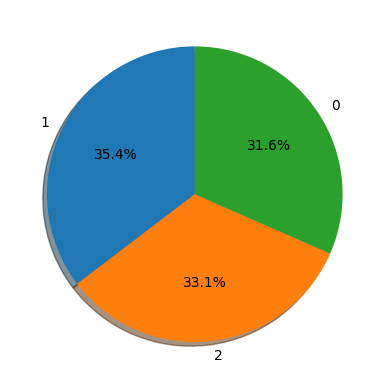

In [ ]:
# Строим круговую диаграмму с соотношением классов
fig1, ax1 = plt.subplots()
ax1.pie(class_counts, labels = class_counts.keys(), shadow=True,
        autopct = '%1.1f%%', startangle=90)
plt.show()

Можно заметить, что классы сбалансированы, т.к. их поровну (ну почти)

### **Посмотрим на изображения из датасета**

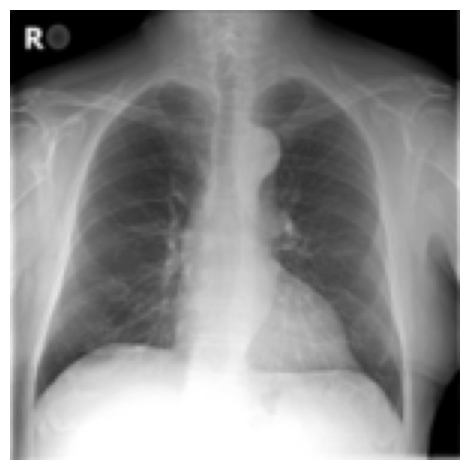

In [ ]:
# Первая картинка из датасета
img, cls = dataset[0]
ts.show(img)

In [ ]:
img.shape

torch.Size([1, 150, 150])

In [ ]:
cls

0

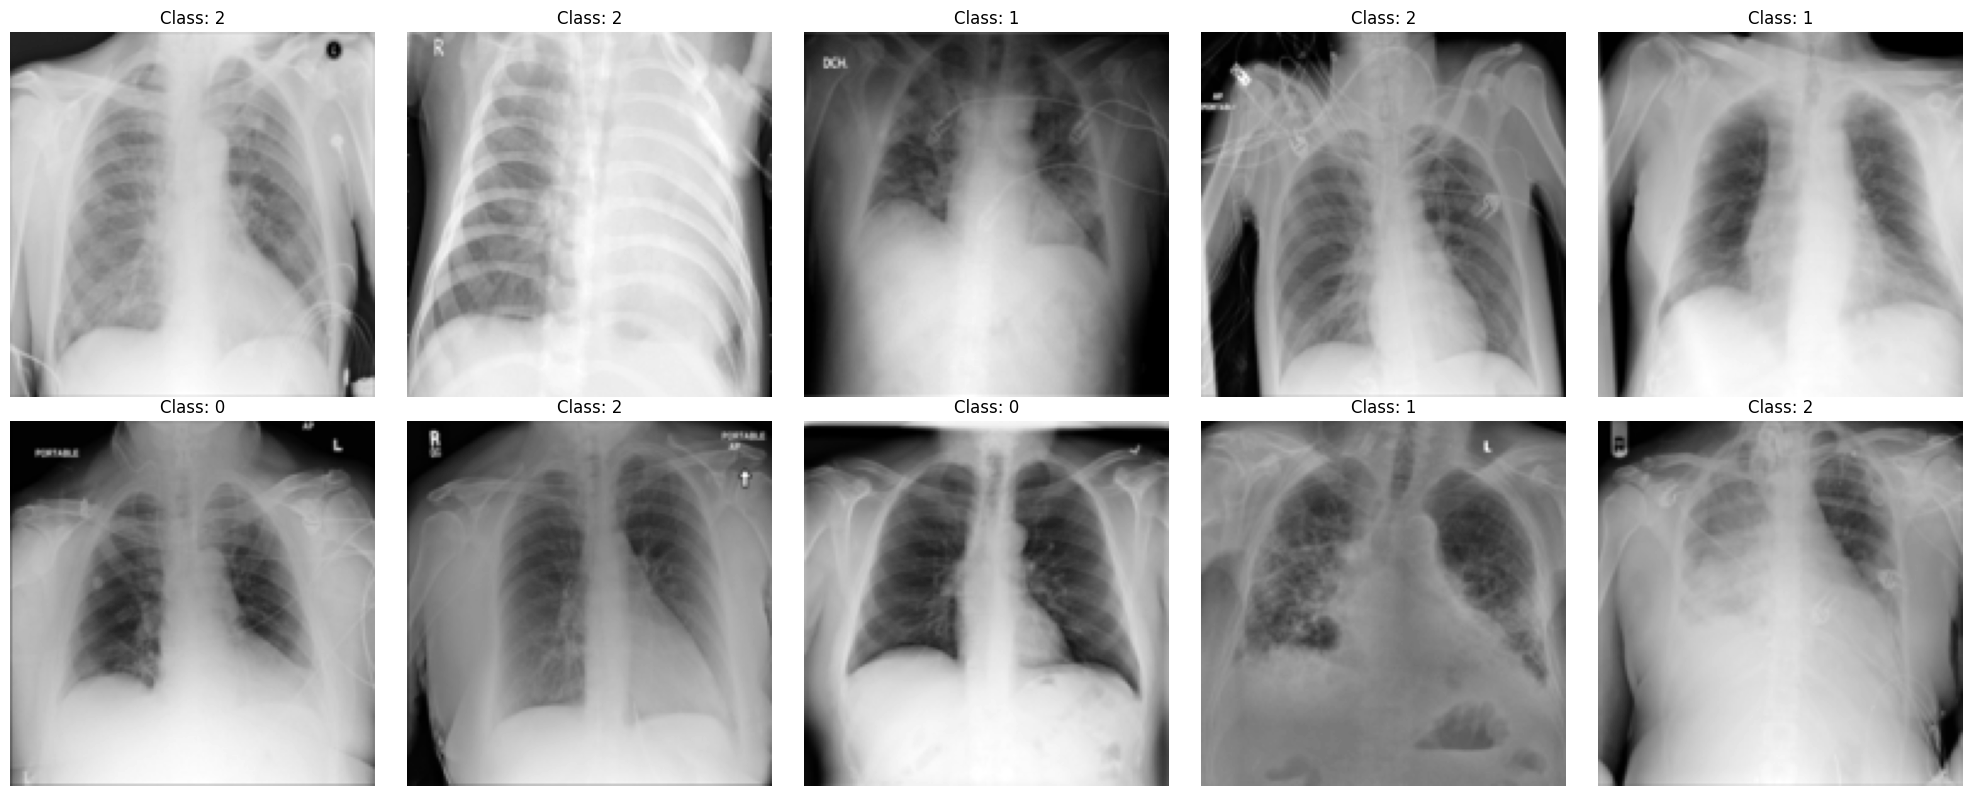

In [ ]:
# отобразим 10 изображений с метками для примера
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))

for i, (image, label) in enumerate(dataloader):
    row = i // 5
    col = i % 5

    ax = axs[row, col]
    ax.imshow(image[0].permute(1, 2, 0), cmap='gray')
    ax.set_title(f'Class: {label.item()}')
    ax.axis('off')

    if i >= 9:
        break

plt.tight_layout()
plt.show()

In [ ]:
# Бьём данные на тестовую и валидационную выборки, сид = 42
trainset, valset = random_split(dataset, [0.8, 0.2], generator=torch.Generator().manual_seed(42))

In [ ]:
# std и mean для нормализации 1-канального изображения
image_data_loader = DataLoader(
    dataset,
    batch_size=len(dataset),
    shuffle=False,
    num_workers=0)


def mean_std(loader):
    images, lebels = next(iter(loader))
    mean, std = images.mean([0,2,3]), images.std([0,2,3])
    return mean, std


mean, std = mean_std(image_data_loader)
print("mean and std: \n", mean, std)

Чтоб при перезапуске не пересчитывать, мы запишем эти значения

In [ ]:
mean = [0.485, 0.456, 0.406]  # 3 канала
std = [0.229, 0.224, 0.225]  # 3 канала

In [ ]:
mean, std = torch.tensor([0.5140]), torch.tensor([0.2469]) # 1 канал

### **Аугментации 1**

In [ ]:
# Аугментации + преобразования для тренировочной выборки
train_transform = transforms.Compose(
    [
      transforms.RandomRotation(10),
      transforms.RandomHorizontalFlip(p=0.4),
      transforms.Normalize(mean = mean, std=std)
    ]
)

### **Аугментации 2**

In [ ]:
# Аугментации
train_transform = transforms.Compose(
    [
      transforms.RandomRotation(15),
      transforms.RandomHorizontalFlip(),
      transforms.RandomAffine(degrees=15, translate=(0.15, 0.15), scale=(0.85, 1.15)),
      transforms.Normalize(mean = mean, std=std)
    ]
)

### **Трансформации для валидации и теста**

In [ ]:
# Преобразования для тренировочной и тестовой выборки
val_transform = transforms.Compose(
    [
      transforms.Normalize(mean=mean, std = std)
    ]
)

# Трансформации для тестовой выборки
test_transform = transforms.Compose(
    [
      torchvision.transforms.Grayscale(num_output_channels=3),  # Для моделей с 3-х канальным входом
      transforms.Resize((150,150)),
      transforms.ToTensor(),
      transforms.Normalize(mean=mean, std = std)
    ]
)

### **Применим трансформации к тренировочной и валидационной выборкам**

In [ ]:
class DatasetFromSubset(Dataset):
    """ Чтоб вернуть обратно в датасет + применить преобразования """
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x).to(device)
        return x, y

    def __len__(self):
        return len(self.subset)

In [ ]:
# Применяем преобразования к тренировочному датасету
trainset_t = DatasetFromSubset(trainset, train_transform)

In [ ]:
# Применяем преобразования к валидационному датасету
valset_t = DatasetFromSubset(valset, val_transform)

In [ ]:
# Смотрим, что все как надо
trainset_t[0][0]

tensor([[[-2.0818, -2.0818, -2.0818,  ..., -2.0818, -2.0818, -2.0818],
         [-2.0818, -2.0818, -2.0818,  ..., -2.0818, -2.0818, -2.0818],
         [-2.0818, -2.0818, -2.0818,  ..., -2.0818, -2.0818, -2.0818],
         ...,
         [-2.0818, -2.0818, -2.0818,  ..., -2.0818, -2.0818, -2.0818],
         [-2.0818, -2.0818, -2.0818,  ..., -2.0818, -2.0818, -2.0818],
         [-2.0818, -2.0818, -2.0818,  ..., -2.0818, -2.0818, -2.0818]]])

In [ ]:
# Тренировочный загрузчик
train_loader = DataLoader(trainset_t, batch_size=64, shuffle=True)
# Валидационный загрузчик
valid_loader = DataLoader(valset_t, batch_size=64, shuffle=False)

## **Построение моделей**

### **Вспомогательные функции**

In [ ]:
def load_model(model, filename, map_location=torch.device('cpu')):
    """ Загрузка модели """
    model.load_state_dict(torch.load(filename, map_location=map_location))

In [ ]:
def load_optimizer(optimizer, filename, map_location=torch.device('cpu')):
    """ Загрузка оптимизатора """
    optimizer.load_state_dict(torch.load(filename, map_location=map_location))

In [ ]:
def train(model: nn.Module, data_loader: DataLoader, optimizer: Optimizer, loss_fn, model_name='model'):
    torch.save(model.state_dict(), f'/content/drive/MyDrive/ModelsData/{model_name}_w')
    torch.save(optimizer.state_dict(), f'/content/drive/MyDrive/ModelsData/{model_name}_optimizer')
    """ Один шаг обучения модели """
    # Обучаем модель
    model.train()

    # Итоговый лосс
    total_loss = 0
    # Всего верно распознано
    total_correct = 0

    for x, y in tqdm(data_loader):
        y = y.to(device)
        optimizer.zero_grad()

        # Предсказание модели
        output = model(x)

        # Считаем лосс
        loss = loss_fn(output, y)

        loss.backward()

        # Добавляем в тоговый лосс
        total_loss += loss.item()

        # Добавляем в общее число верно распознанных
        total_correct += (output.argmax(dim=1) == y).sum().item()

        # Оптимизируем веса
        optimizer.step()

    # Возвращаем лосс и f1 метрику
    return total_loss / len(data_loader), total_correct / len(data_loader.dataset)


In [ ]:
@torch.inference_mode()
def evaluate(model: nn.Module, data_loader: DataLoader, loss_fn):
    """ Для подсчета лосс и метрики на валидационной выборке """
    model.eval()

    # Итоговый лосс
    total_loss = 0
    # Всего верно распознано
    total_correct = 0

    for x, y in tqdm(data_loader):
        y = y.to(device)
        # Предсказание модели
        output = model(x)

        # Считаем лосс
        loss = loss_fn(output, y)

        # Добавляем в тоговый лосс
        total_loss += loss.item()

        # Добавляем в общее число верно распознанных
        total_correct += (output.argmax(dim=1) == y).sum().item()

    # Возвращаем лосс и f1 метрику
    return total_loss / len(data_loader), total_correct / len(data_loader.dataset)

In [ ]:
sns.set(style='darkgrid')


def plot_stats(
    train_loss: list[float],
    valid_loss: list[float],
    train_accuracy: list[float],
    valid_accuracy: list[float],
    title: str
):
    """ Строим графики """
    plt.figure(figsize=(16, 8))

    plt.title(title + ' loss')

    plt.plot(train_loss, label='Train loss')
    plt.plot(valid_loss, label='Valid loss')
    plt.legend()

    plt.show()

    plt.figure(figsize=(16, 8))

    plt.title(title + ' accuracy')

    plt.plot(train_accuracy, label='Train accuracy')
    plt.plot(valid_accuracy, label='Valid accuracy')
    plt.legend()

    plt.show()

In [ ]:
from IPython.display import clear_output


def fit(model, train_loader, valid_loader, optimizer, loss_fn, num_epochs, title):
    """ Обучаем модель """
    train_loss_history, valid_loss_history = [], []
    train_accuracy_history, valid_accuracy_history = [], []

    for epoch in range(num_epochs):
        train_loss, train_accuracy = train(model, train_loader, optimizer, loss_fn, title)
        valid_loss, valid_accuracy = evaluate(model, valid_loader, loss_fn)

        train_loss_history.append(train_loss)
        valid_loss_history.append(valid_loss)

        train_accuracy_history.append(train_accuracy)
        valid_accuracy_history.append(valid_accuracy)

        clear_output()

        plot_stats(
            train_loss_history, valid_loss_history,
            train_accuracy_history, valid_accuracy_history,
            title
        )

### **Модель 1**

In [ ]:
class Model1(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=5),
            nn.LeakyReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(in_channels=16, out_channels=1, kernel_size=5),
            nn.LeakyReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Flatten(),

            nn.Linear(53 * 53, 16),
            nn.LeakyReLU(),
            nn.Linear(16, 3),

            nn.Softmax(dim = 1)
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
model_1 = Model1()

In [ ]:
model_1.to(device)

ModelOne(
  (net): Sequential(
    (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1))
    (1): LeakyReLU(negative_slope=0.01)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 1, kernel_size=(5, 5), stride=(1, 1))
    (4): LeakyReLU(negative_slope=0.01)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=2809, out_features=16, bias=True)
    (8): LeakyReLU(negative_slope=0.01)
    (9): Linear(in_features=16, out_features=3, bias=True)
    (10): Softmax(dim=1)
  )
)

In [ ]:
summary(model_1, (1, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 220, 220]             416
         LeakyReLU-2         [-1, 16, 220, 220]               0
         MaxPool2d-3         [-1, 16, 110, 110]               0
            Conv2d-4          [-1, 1, 106, 106]             401
         LeakyReLU-5          [-1, 1, 106, 106]               0
         MaxPool2d-6            [-1, 1, 53, 53]               0
           Flatten-7                 [-1, 2809]               0
            Linear-8                   [-1, 16]          44,960
         LeakyReLU-9                   [-1, 16]               0
           Linear-10                    [-1, 3]              51
          Softmax-11                    [-1, 3]               0
Total params: 45,828
Trainable params: 45,828
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.19
Forward/ba

In [ ]:
optimizer = torch.optim.Adam(model_1.parameters(), lr=1e-3)

In [ ]:
loss_fn = nn.CrossEntropyLoss()

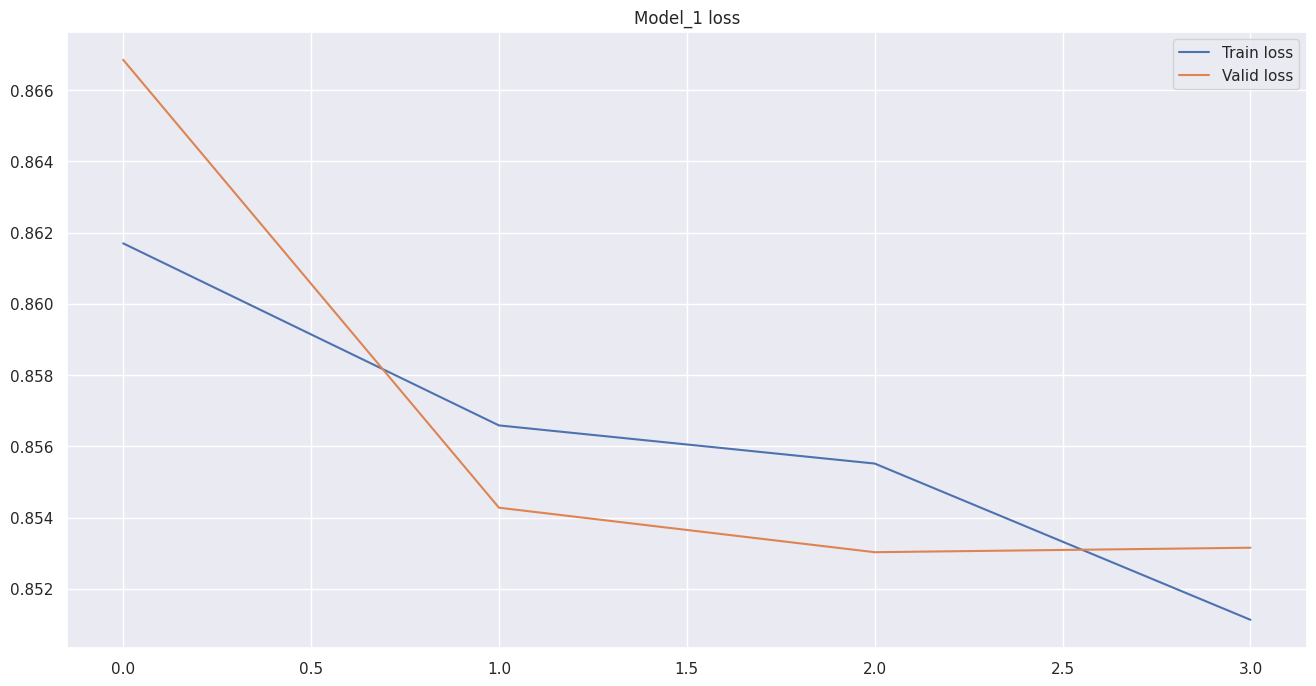

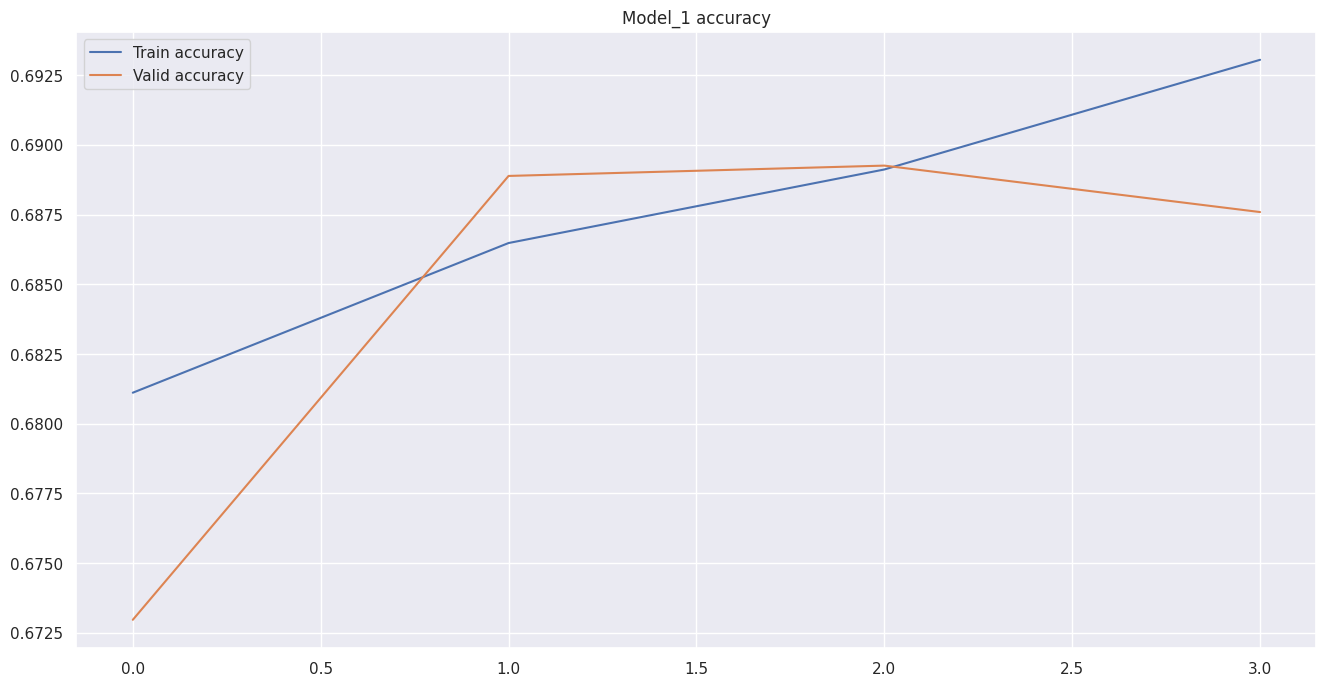

In [ ]:
fit(model_1, train_loader, valid_loader, optimizer, loss_fn, 4, 'Model_1')

### **Модель 2-3 ResNet**

#### **Общая структура**

In [ ]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_planes, planes, stride=1, is_last=False):
        super(BasicBlock, self).__init__()
        self.is_last = is_last
        self.conv1 = nn.Conv2d(in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_planes != self.expansion * planes:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_planes, self.expansion * planes, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(self.expansion * planes)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        preact = out
        out = F.relu(out)
        if self.is_last:
            return out, preact
        else:
            return out

In [ ]:
class ResNet(nn.Module):
    def __init__(self, block, num_blocks, in_channel=3, zero_init_residual=False):
        super(ResNet, self).__init__()
        self.in_planes = 64

        self.conv1 = nn.Conv2d(in_channel, 64, kernel_size=3, stride=1, padding=1,
                               bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.layer1 = self._make_layer(block, 64, num_blocks[0], stride=1)
        self.layer2 = self._make_layer(block, 128, num_blocks[1], stride=2)
        self.layer3 = self._make_layer(block, 256, num_blocks[2], stride=2)
        self.layer4 = self._make_layer(block, 512, num_blocks[3], stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, (nn.BatchNorm2d, nn.GroupNorm)):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

        if zero_init_residual:
            for m in self.modules():
              nn.init.constant_(m.bn2.weight, 0)

    def _make_layer(self, block, planes, num_blocks, stride):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for i in range(num_blocks):
            stride = strides[i]
            layers.append(block(self.in_planes, planes, stride))
            self.in_planes = planes * block.expansion
        return nn.Sequential(*layers)

    def forward(self, x, layer=100):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.layer4(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        return out

In [ ]:
def resnet18():
    layers=[2, 2, 2, 2]
    model = ResNet(BasicBlock, layers)
    return model

In [ ]:
def resnet34():
    layers=[3, 4, 6, 3]
    model = ResNet(BasicBlock, layers)
    return model

In [ ]:
models_settings = {
    'resnet18': resnet18,
    'resnet34': resnet34
}

In [ ]:
class ResNetModel(nn.Module):
    def __init__(self, model_name='resnet34', feat_dim=3):
        super(ResNetModel, self).__init__()
        self.encoder = models_settings[model_name]()
        self.head = nn.Sequential(
            nn.Linear(512, 512),
            nn.ReLU(inplace=True),
            nn.Linear(512, feat_dim)
        )

    def forward(self, x):
        feat = self.encoder(x)
        feat = F.normalize(self.head(feat), dim=1)
        return feat

#### **Модель 2 ( ResNet38 ) + Аугментации №1**

In [ ]:
model_2 = ResNetModel(model_name='resnet34', feat_dim=3)

In [ ]:
model_2.to(device)

ResNetModel(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (layer1): Sequential(
      (0): ResBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): ResBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn

In [ ]:
summary(model_2, (3, 150, 150))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 150, 150]             576
       BatchNorm2d-2         [-1, 64, 150, 150]             128
            Conv2d-3         [-1, 64, 150, 150]          36,864
       BatchNorm2d-4         [-1, 64, 150, 150]             128
            Conv2d-5         [-1, 64, 150, 150]          36,864
       BatchNorm2d-6         [-1, 64, 150, 150]             128
          ResBlock-7         [-1, 64, 150, 150]               0
            Conv2d-8         [-1, 64, 150, 150]          36,864
       BatchNorm2d-9         [-1, 64, 150, 150]             128
           Conv2d-10         [-1, 64, 150, 150]          36,864
      BatchNorm2d-11         [-1, 64, 150, 150]             128
         ResBlock-12         [-1, 64, 150, 150]               0
           Conv2d-13         [-1, 64, 150, 150]          36,864
      BatchNorm2d-14         [-1, 64, 1

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_2.parameters(), lr=1e-3)

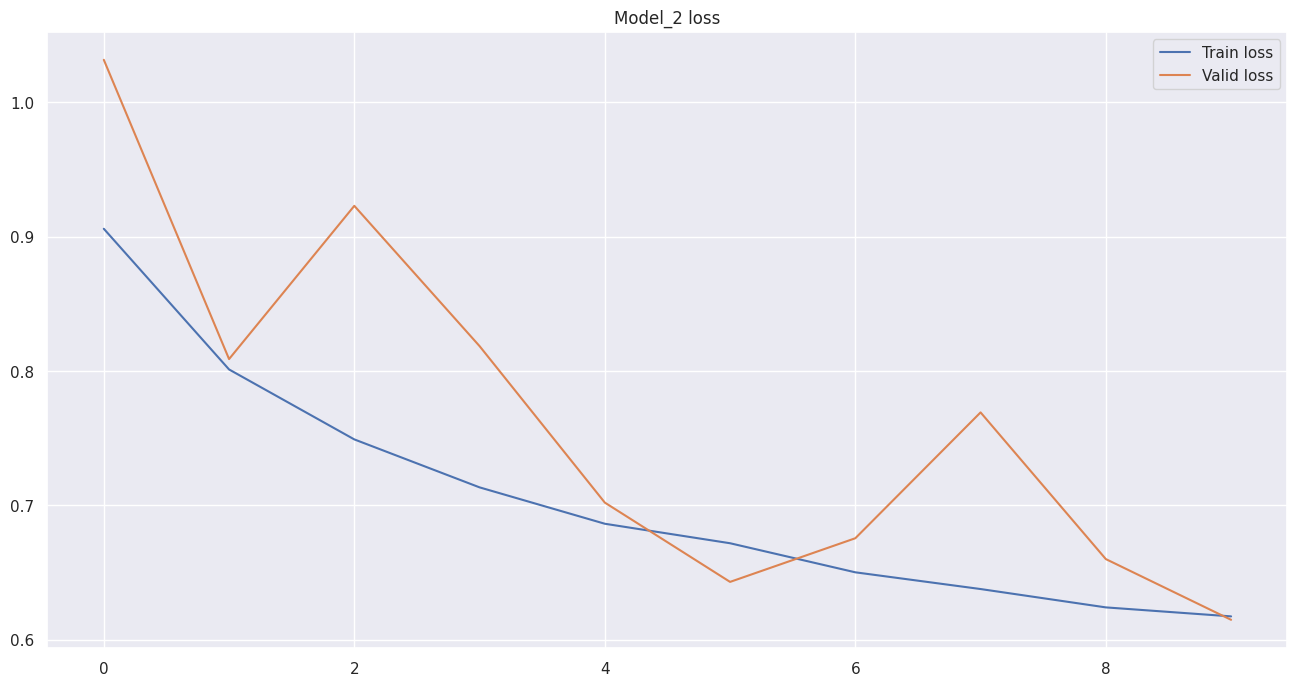

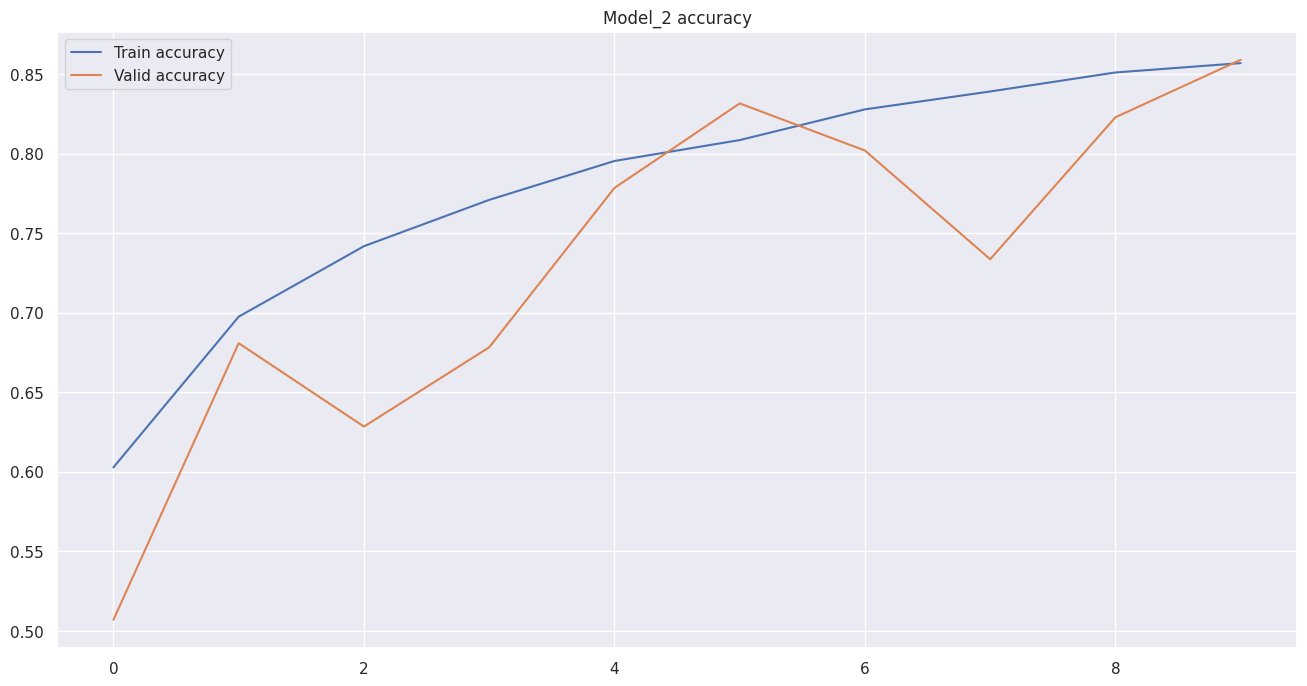

In [ ]:
fit(model_2, train_loader, valid_loader, optimizer, loss_fn, 10, 'Model_2')

#### **Модель 3 ( ResNet18 ) + Аугментации №2**

In [ ]:
model_3 = ResNetModel(model_name='resnet18', feat_dim=3)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_3.parameters(), lr=1e-3)

In [ ]:
model_3.to(device)

ResNetModel(
  (encoder): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (layer1): Sequential(
      (0): ResBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (shortcut): Sequential()
      )
      (1): ResBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn

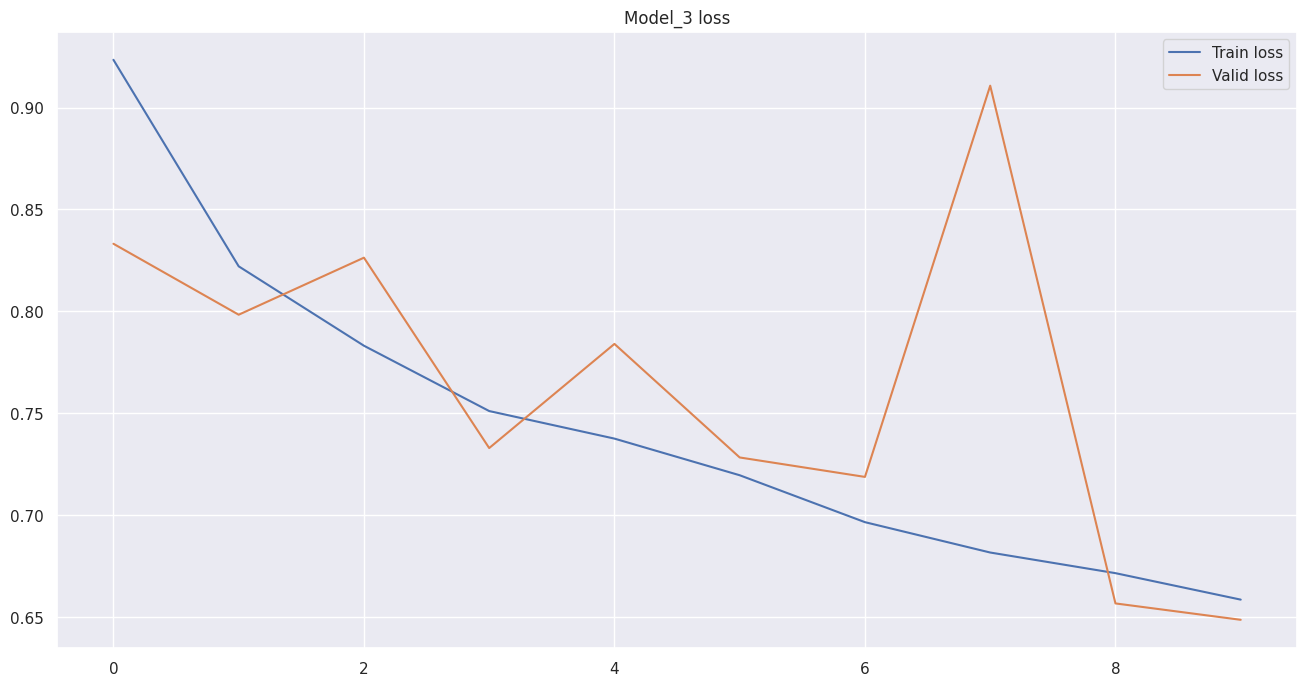

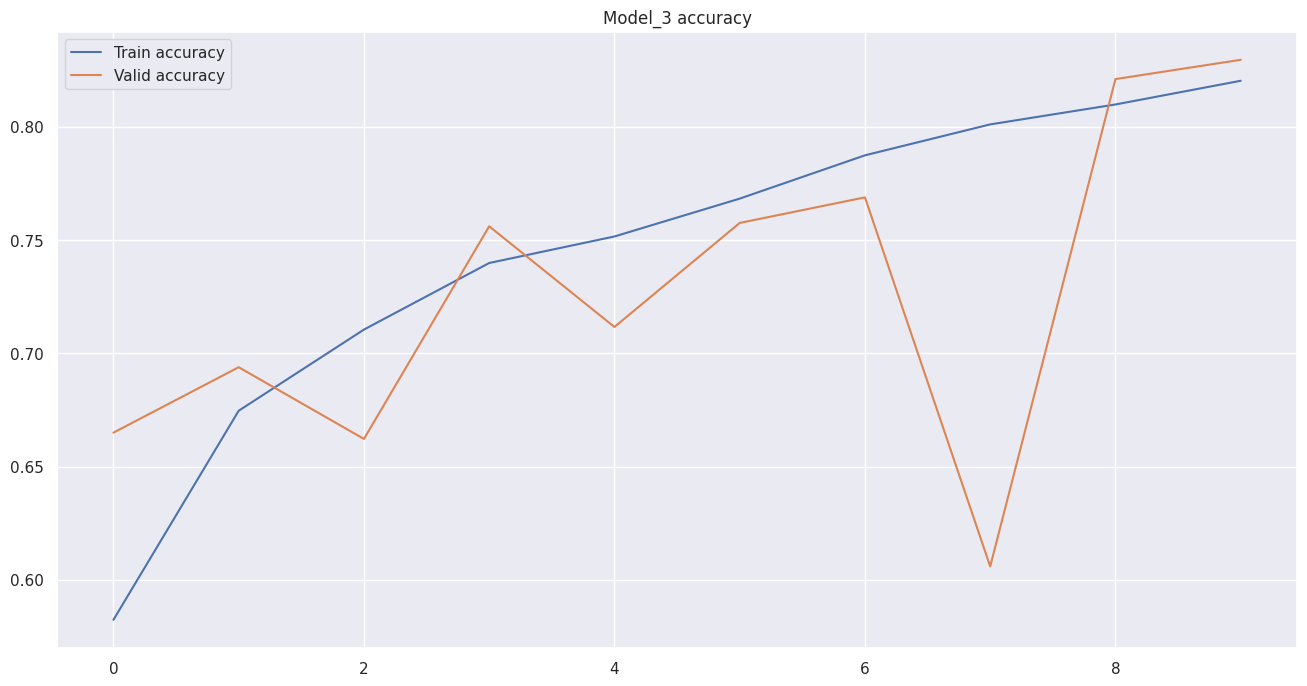

In [ ]:
fit(model_3, train_loader, valid_loader, optimizer, loss_fn, 10, 'Model_3')

### **Модель 4**

In [ ]:
class Model4(nn.Module):
    def __init__(self, num_classes=3):
        super(Model4, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 37 * 37, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

# Создание экземпляра модели
model_4 = Model4()

In [ ]:
summary(model_4, (3, 150, 150))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 150, 150]             448
              ReLU-2         [-1, 16, 150, 150]               0
         MaxPool2d-3           [-1, 16, 75, 75]               0
            Conv2d-4           [-1, 32, 75, 75]           4,640
              ReLU-5           [-1, 32, 75, 75]               0
         MaxPool2d-6           [-1, 32, 37, 37]               0
           Flatten-7                [-1, 43808]               0
            Linear-8                  [-1, 128]       5,607,552
              ReLU-9                  [-1, 128]               0
           Linear-10                    [-1, 3]             387
Total params: 5,613,027
Trainable params: 5,613,027
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.26
Forward/backward pass size (MB): 9.60
Params size (MB): 21.41
Estima

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_4.parameters(), lr=1e-3)

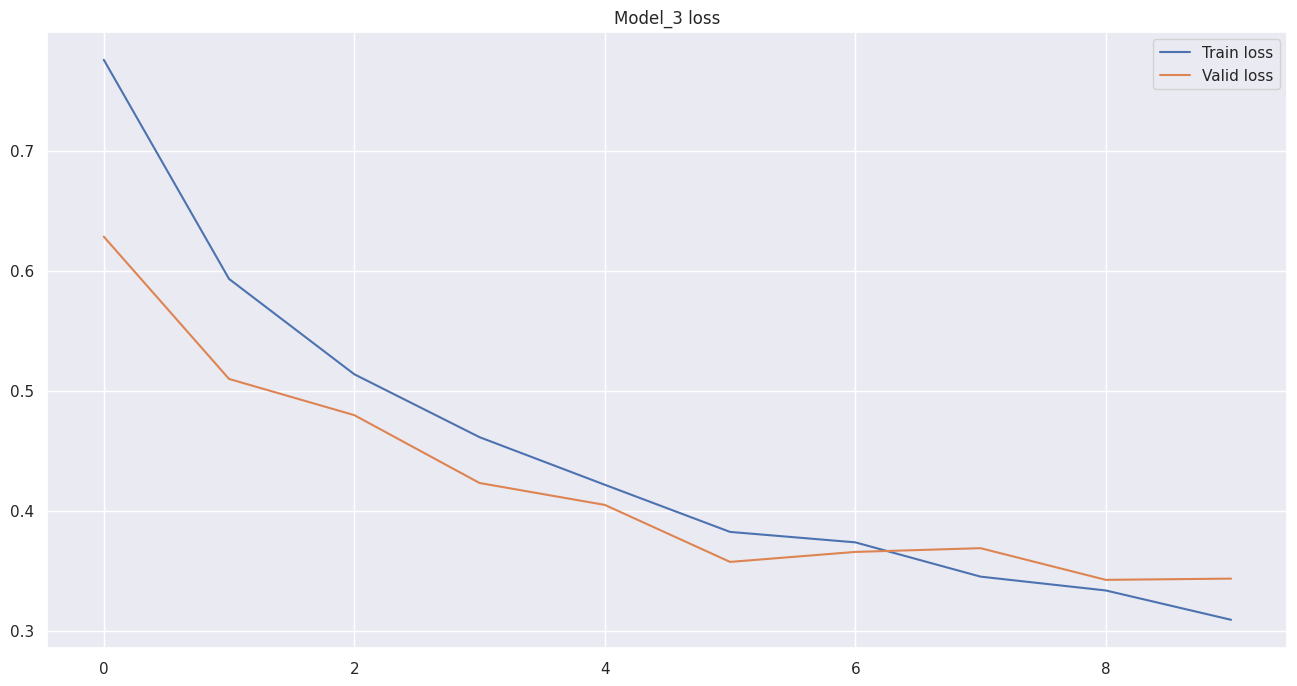

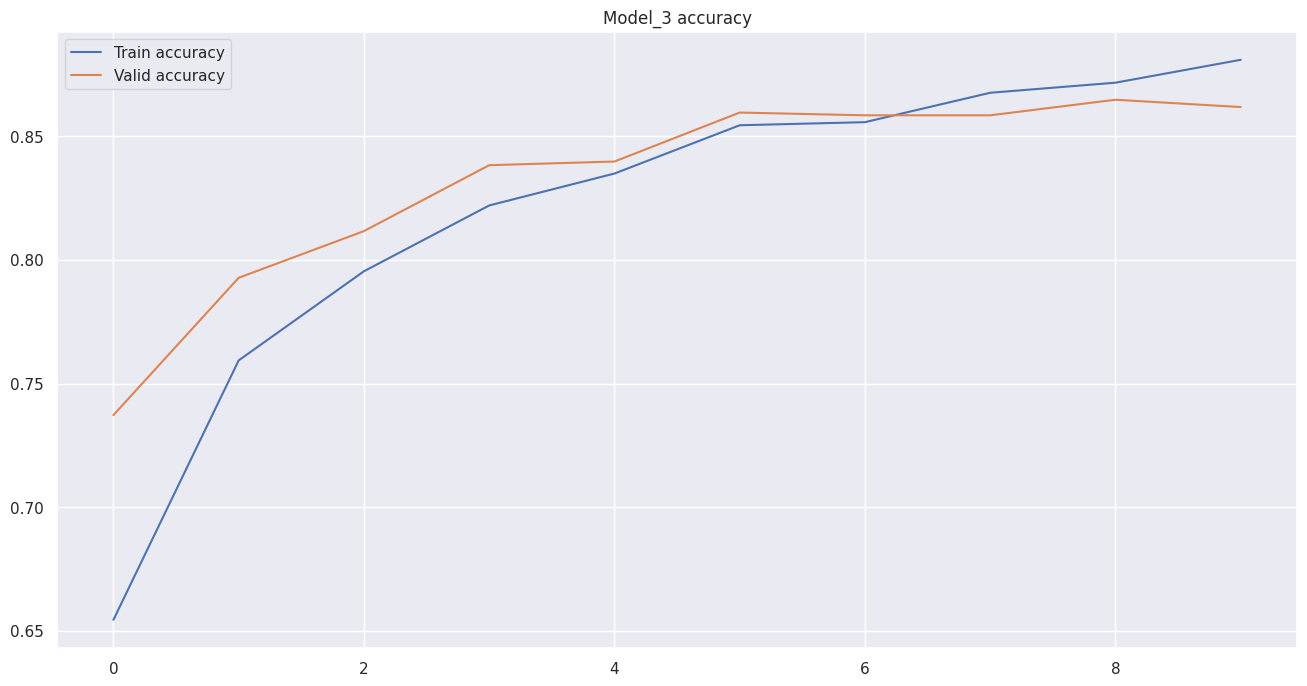

In [ ]:
# Нумерация моделей при разработке чуть поехала, поэтому на графике название некорректное :)
fit(model_4, train_loader, valid_loader, optimizer, loss_fn, 10, 'Model_4')

### **Модель 5**

In [ ]:
class Model5(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),
            nn.Flatten(),
            nn.Linear(18 * 18 * 128, 512),
            nn.BatchNorm1d(512),
            nn.Dropout(p=0.3),
            nn.ReLU(),
            nn.Linear(512, 3)
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
model_5 = Model5().to(device)

In [ ]:
summary(model_5, (1, 150, 150))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 150, 150]             320
       BatchNorm2d-2         [-1, 32, 150, 150]              64
              ReLU-3         [-1, 32, 150, 150]               0
            Conv2d-4         [-1, 32, 150, 150]           9,248
       BatchNorm2d-5         [-1, 32, 150, 150]              64
              ReLU-6         [-1, 32, 150, 150]               0
         MaxPool2d-7           [-1, 32, 75, 75]               0
         Dropout2d-8           [-1, 32, 75, 75]               0
            Conv2d-9           [-1, 64, 75, 75]          18,496
      BatchNorm2d-10           [-1, 64, 75, 75]             128
             ReLU-11           [-1, 64, 75, 75]               0
           Conv2d-12           [-1, 64, 75, 75]          36,928
      BatchNorm2d-13           [-1, 64, 75, 75]             128
             ReLU-14           [-1, 64,

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_5.parameters(), lr=1e-3)

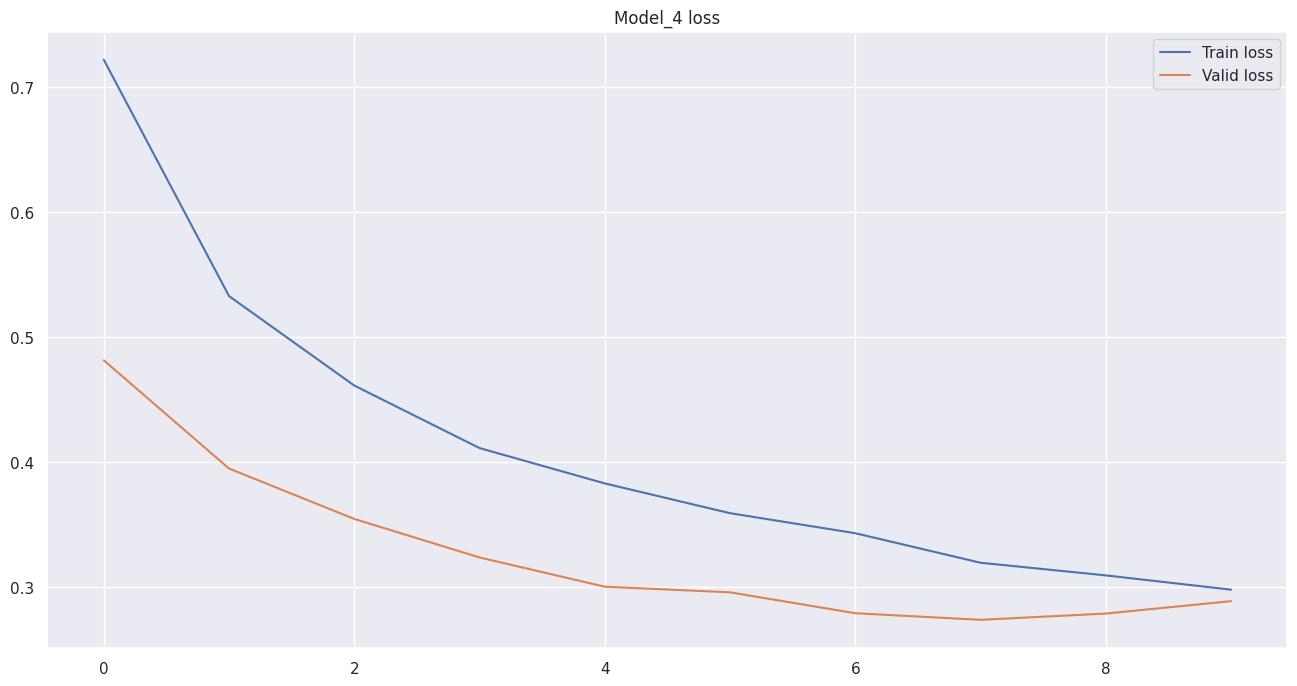

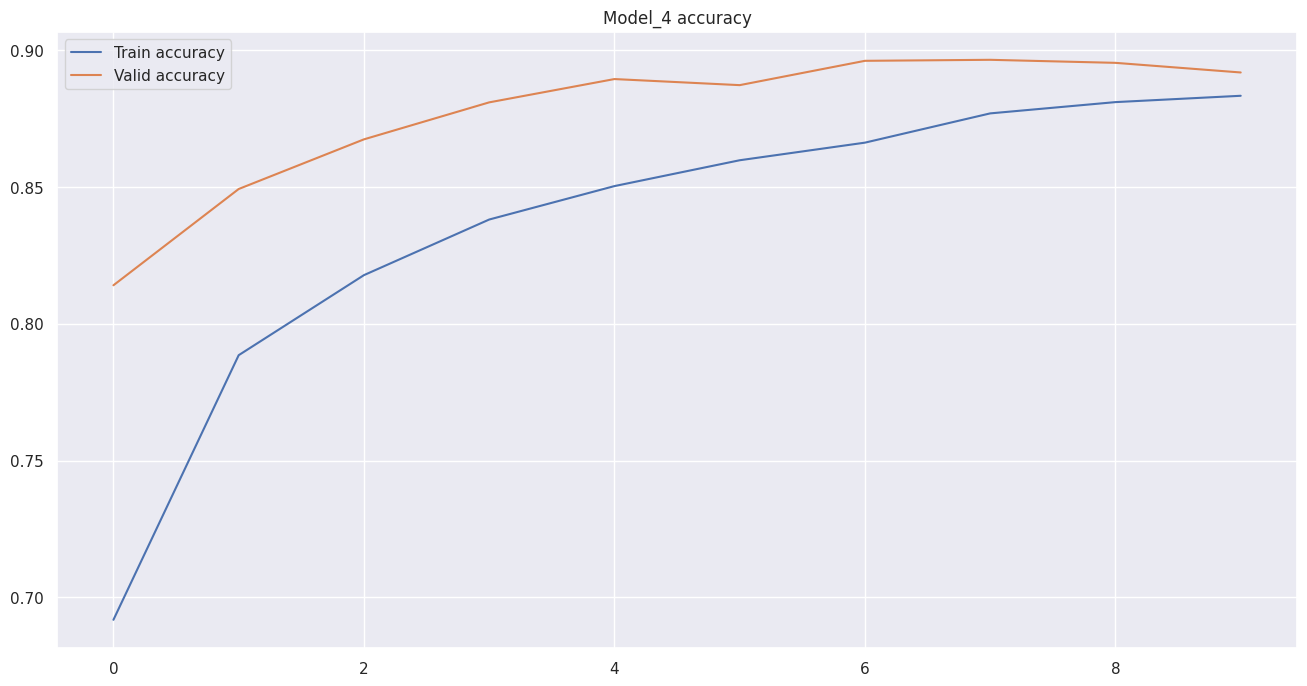

In [ ]:
fit(model_5, train_loader, valid_loader, optimizer, loss_fn, 10, 'Model_5')

### **Модель 6**

In [ ]:
class Model6(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            # Добавлен новый блок свертки
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            # Увеличен размер полносвязанного слоя
            nn.Flatten(),
            nn.Linear(18 * 18 * 128, 1024),
            nn.BatchNorm1d(1024),
            nn.Dropout(p=0.3),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.Dropout(p=0.3),
            nn.ReLU(),
            nn.Linear(512, 3)
        )

    def forward(self, x):
        return self.net(x)


In [ ]:
model_6 = Model6().to(device)

In [ ]:
summary(model_6, (1, 150, 150))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 150, 150]             320
       BatchNorm2d-2         [-1, 32, 150, 150]              64
              ReLU-3         [-1, 32, 150, 150]               0
            Conv2d-4         [-1, 32, 150, 150]           9,248
       BatchNorm2d-5         [-1, 32, 150, 150]              64
              ReLU-6         [-1, 32, 150, 150]               0
         MaxPool2d-7           [-1, 32, 75, 75]               0
         Dropout2d-8           [-1, 32, 75, 75]               0
            Conv2d-9           [-1, 64, 75, 75]          18,496
      BatchNorm2d-10           [-1, 64, 75, 75]             128
             ReLU-11           [-1, 64, 75, 75]               0
           Conv2d-12           [-1, 64, 75, 75]          36,928
      BatchNorm2d-13           [-1, 64, 75, 75]             128
             ReLU-14           [-1, 64,

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_6.parameters(), lr=1e-3)

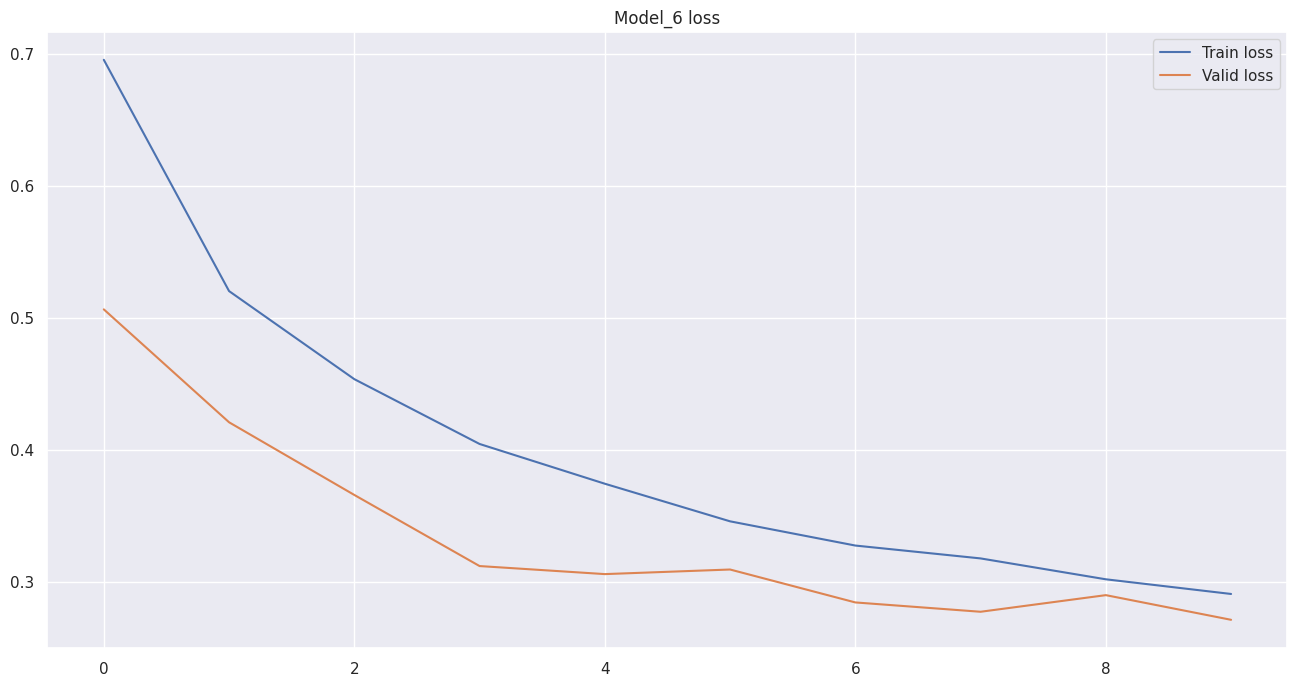

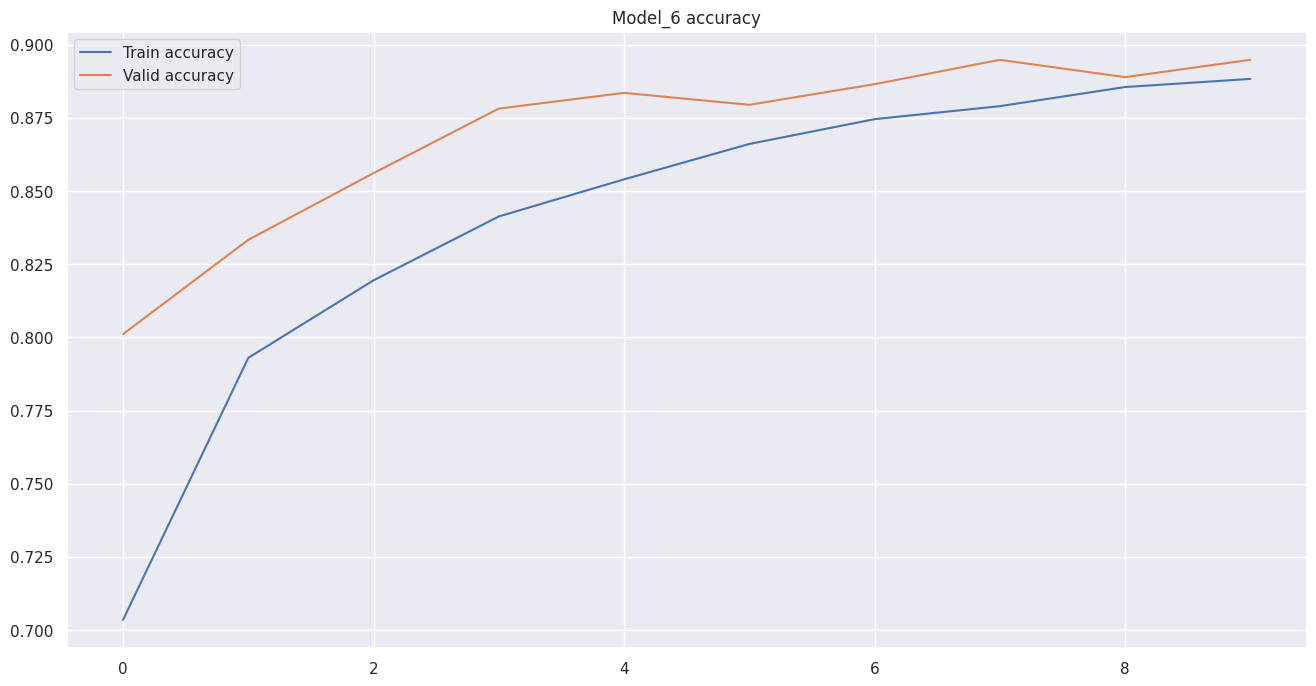

In [ ]:
fit(model_6, train_loader, valid_loader, optimizer, loss_fn, 10, 'Model_6')

### **Модель 7**

In [ ]:
class Model7(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            # Добавлен новый блок свёртки
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(p=0.2),

            nn.Flatten(),

            nn.Linear(256 * 9 * 9, 1024),
            nn.BatchNorm1d(1024),
            nn.Dropout(p=0.3),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.Dropout(p=0.3),
            nn.ReLU(),
            nn.Linear(512, 3)
        )

    def forward(self, x):
        return self.net(x)


In [ ]:
model_7 = Model7().to(device)

In [ ]:
summary(model_7, (1, 150, 150))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 150, 150]             320
       BatchNorm2d-2         [-1, 32, 150, 150]              64
              ReLU-3         [-1, 32, 150, 150]               0
            Conv2d-4         [-1, 32, 150, 150]           9,248
       BatchNorm2d-5         [-1, 32, 150, 150]              64
              ReLU-6         [-1, 32, 150, 150]               0
         MaxPool2d-7           [-1, 32, 75, 75]               0
         Dropout2d-8           [-1, 32, 75, 75]               0
            Conv2d-9           [-1, 64, 75, 75]          18,496
      BatchNorm2d-10           [-1, 64, 75, 75]             128
             ReLU-11           [-1, 64, 75, 75]               0
           Conv2d-12           [-1, 64, 75, 75]          36,928
      BatchNorm2d-13           [-1, 64, 75, 75]             128
             ReLU-14           [-1, 64,

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_7.parameters(), lr=1e-3)

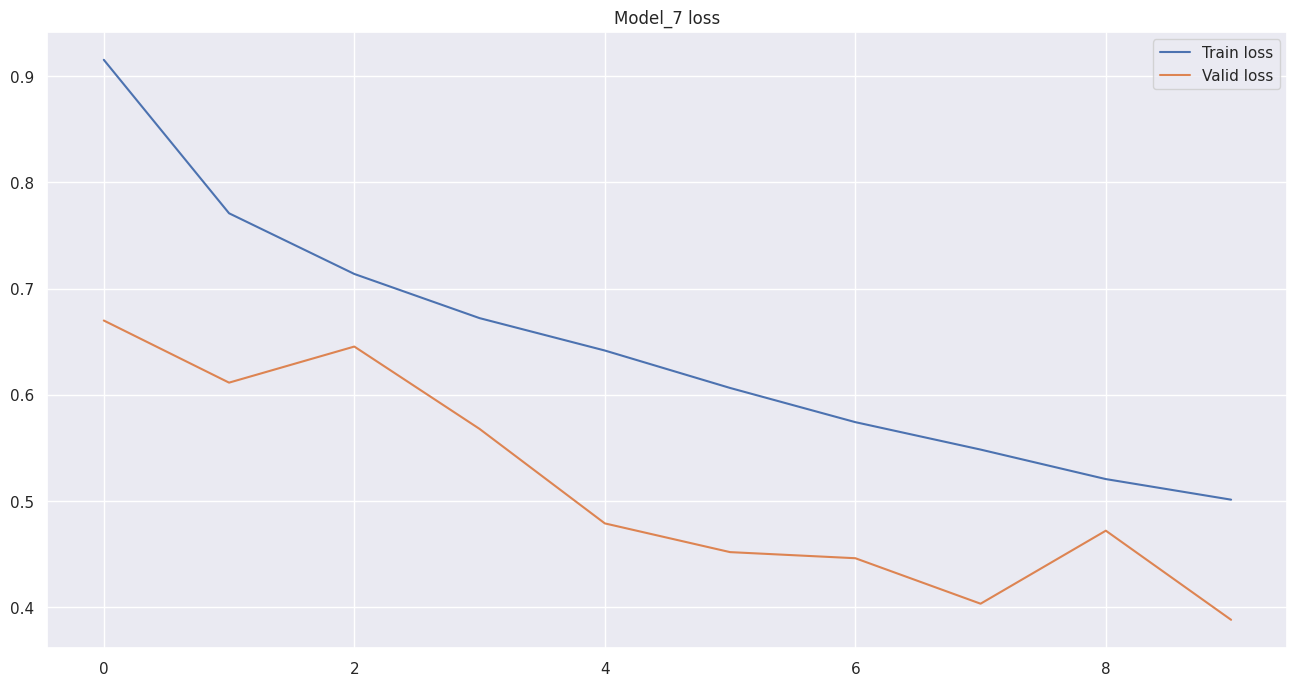

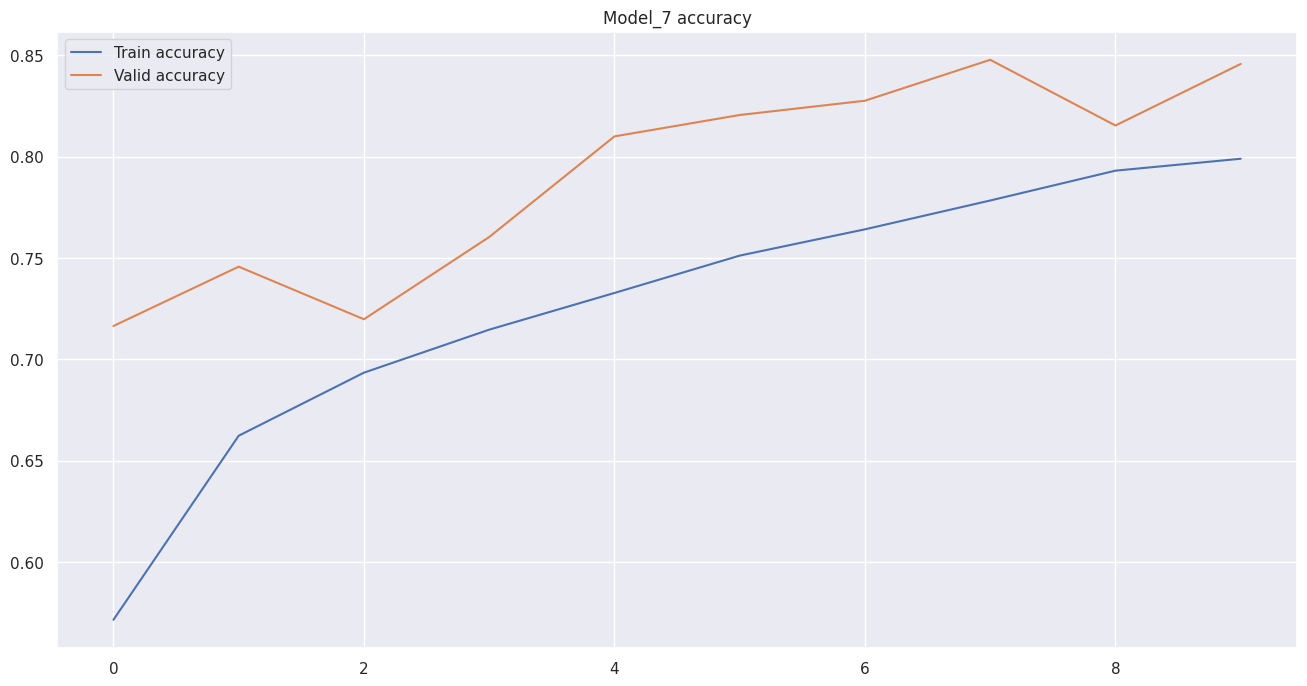

In [ ]:
fit(model_7, train_loader, valid_loader, optimizer, loss_fn, 10, 'Model_7')

Дальше расширять модель походу уже нет смысла. Начинает моделька становится сильно перегруженной - упали accuracy и f score, а также начались проблемы со сходимостью модели. Тогда оставим модель №6 как самый удачный вариант :) Но это еще не все - попробуем поработать с масками для треиновых картинок и посмотреть станет ли лучше или хуже. Пробовать будем как раз на архитектуре 6-й модели

## **Работа с масками**

In [ ]:
from torch.utils.data import Dataset, DataLoader

class CustomMaskDataset(Dataset):    # создание класса путём объединения меток и изображений + применение масок
    def __init__(self, data_dir, csv_file, masks_dir, transform=None):
        self.data_dir = data_dir
        self.data_df = pd.read_csv(csv_file, index_col='id')
        self.masks_dir = masks_dir
        self.transform = transform
        self.images = os.listdir(data_dir)
        self.masks = [os.path.join(masks_dir, mask_name) for mask_name in os.listdir(masks_dir)]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_name = self.images[idx]
        image_path = os.path.join(self.data_dir, image_name)
        image = Image.open(image_path)

        img_id = int(image_name.split('_')[-1].split('.')[0])
        label = self.data_df.loc[img_id, 'target_feature']

        # Преобразование изображения в массив numpy
        image_np = np.array(image)

        # Применение маски к изображению
        mask_path = self.masks[idx]
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        masked_image = cv2.bitwise_and(image_np, image_np, mask=mask)

        # Преобразование обратно в изображение Pillow
        masked_image_pil = Image.fromarray(masked_image)

        if self.transform:
            masked_image_pil = self.transform(masked_image_pil)

        return masked_image_pil, label

In [ ]:
dataset = CustomMaskDataset("data/train_images", "data/train_answers.csv", "data/train_lung_masks", transform=transform_1)

# Создаем DataLoader для итерации по датасету
dataloader = DataLoader(dataset, batch_size=1, shuffle=True)

In [ ]:
# Бьём данные на тестовую и валидационную выборки, сид = 42
trainset, valset = random_split(dataset, [0.8, 0.2], generator=torch.Generator().manual_seed(42))

In [ ]:
# Применяем преобразования к тренировочному датасету
trainset_t = DatasetFromSubset(trainset, train_transform)

In [ ]:
# Применяем преобразования к валидационному датасету
valset_t = DatasetFromSubset(valset, val_transform)

In [ ]:
# Тренировочный загрузчик
train_loader = DataLoader(trainset_t, batch_size=64, shuffle=True)
# Валидационный загрузчик
valid_loader = DataLoader(valset_t, batch_size=64, shuffle=False)

In [ ]:
dataset[1]

(tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]]),
 0)

In [ ]:
dataset[1][0].shape

torch.Size([1, 150, 150])

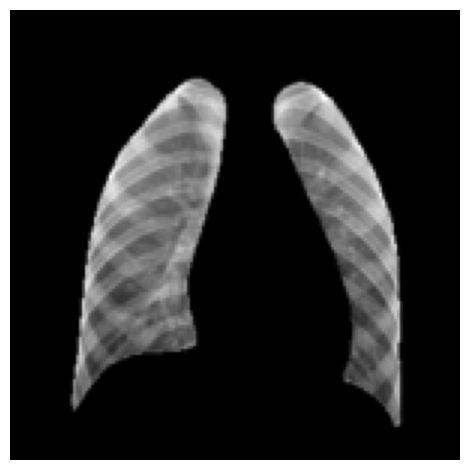

In [ ]:
# пример
img, cls = dataset[1]
ts.show(img)

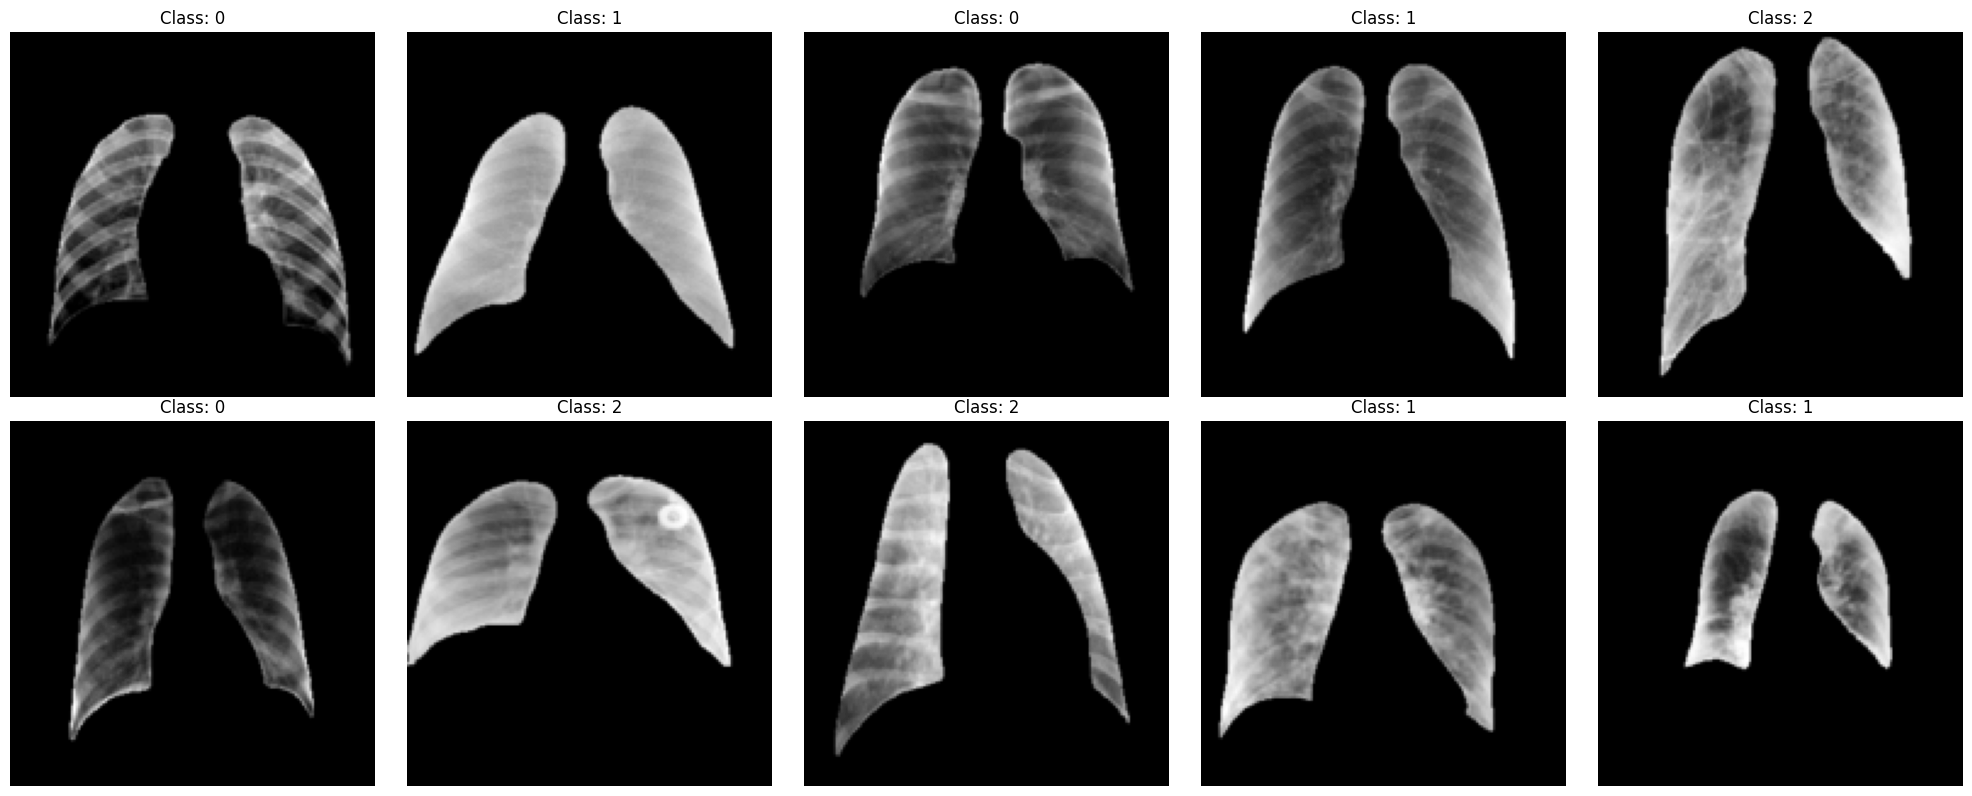

In [ ]:
# отобразим 10 изображений с метками для примера
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))

for i, (image, label) in enumerate(dataloader):
    row = i // 5
    col = i % 5

    ax = axs[row, col]
    ax.imshow(image[0].permute(1, 2, 0), cmap='gray')
    ax.set_title(f'Class: {label.item()}')
    ax.axis('off')

    if i >= 9:
        break

plt.tight_layout()
plt.show()

Выведем по 10 изображений каждого класса:

---



In [ ]:
# Фильтруем данные для классов
class_0_dataset =  []
class_1_dataset =  []
class_2_dataset =  []
for image, label in dataset:
    if label == 0:
      class_0_dataset.append((image, label))
    elif label == 1:
      class_1_dataset.append((image, label))
    else:
      class_2_dataset.append((image, label))

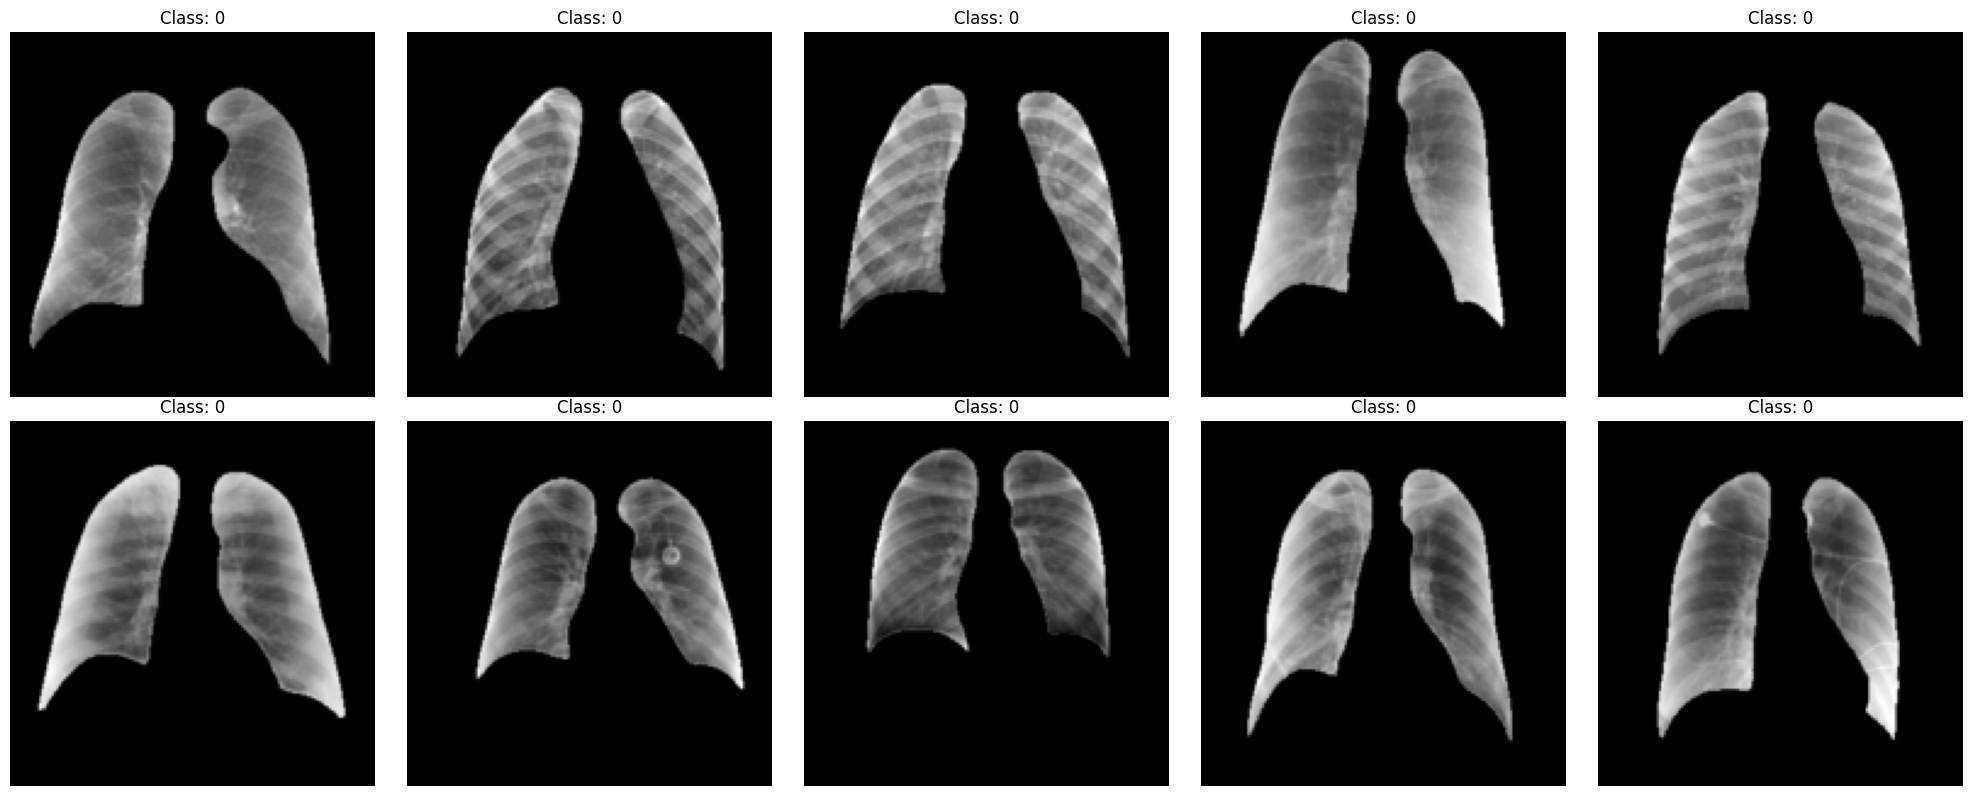

In [ ]:
# Отображаем 10 изображений класса "0"
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))

for i, (image, label) in enumerate(class_0_dataset):
    if i >= 10:
        break

    row = i // 5
    col = i % 5

    ax = axs[row, col]
    ax.imshow(image.permute(1, 2, 0), cmap='gray')
    ax.set_title(f'Class: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

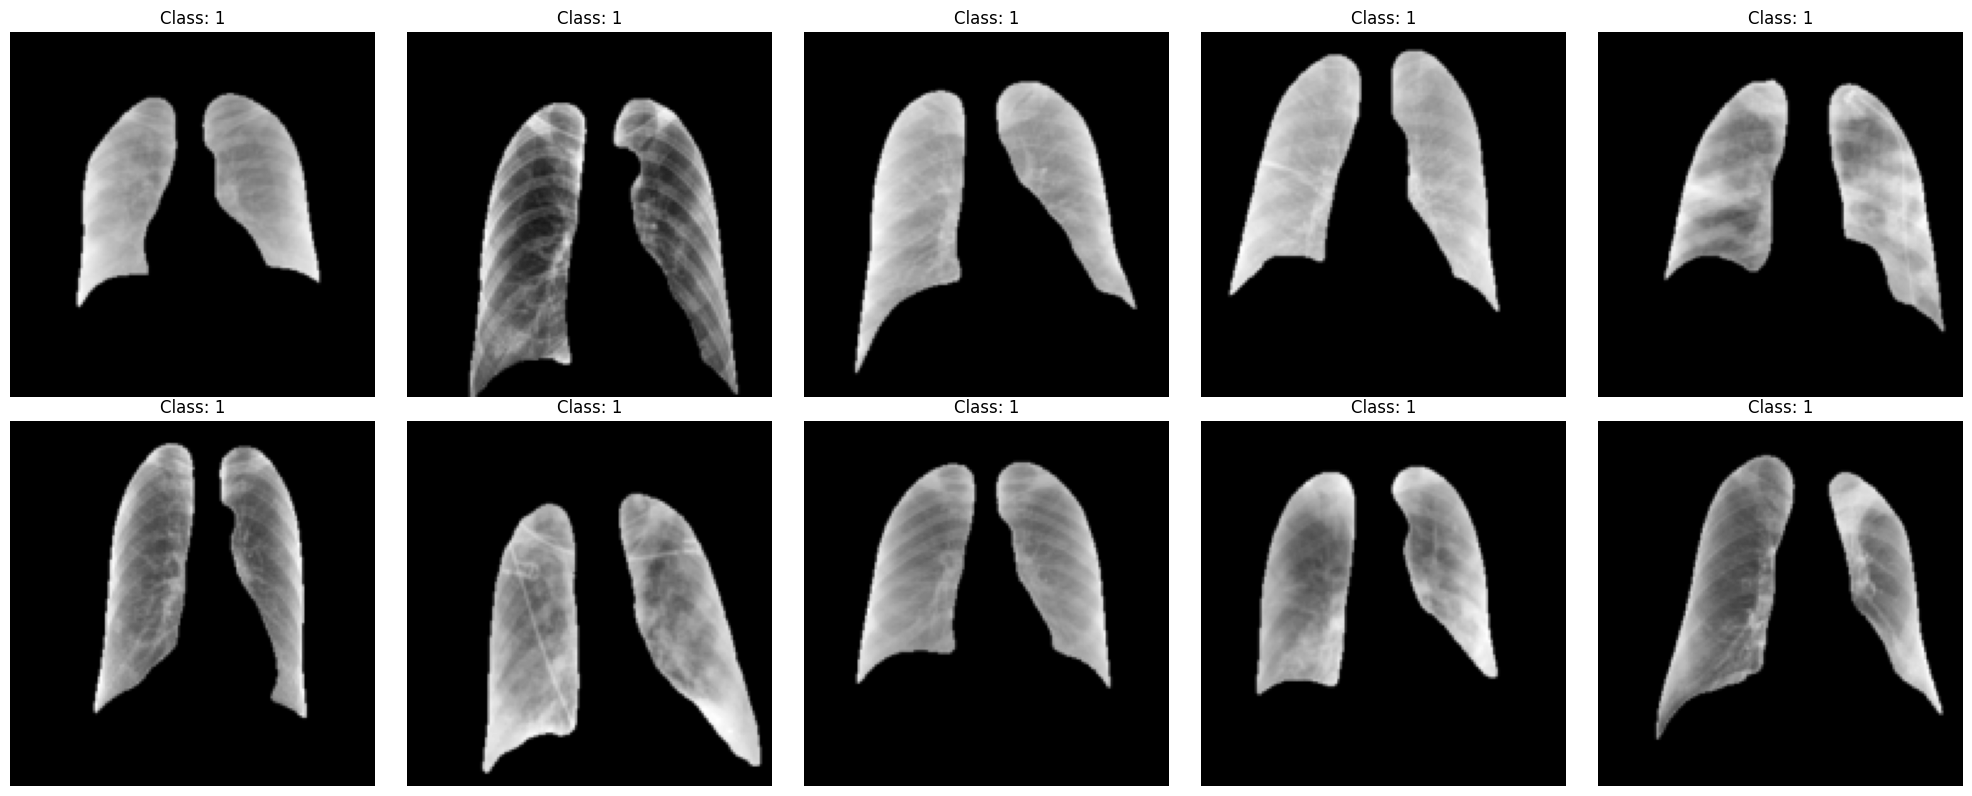

In [ ]:
# Отображаем 10 изображений класса "1"
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))

for i, (image, label) in enumerate(class_1_dataset):
    if i >= 10:
        break

    row = i // 5
    col = i % 5

    ax = axs[row, col]
    ax.imshow(image.permute(1, 2, 0), cmap='gray')
    ax.set_title(f'Class: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

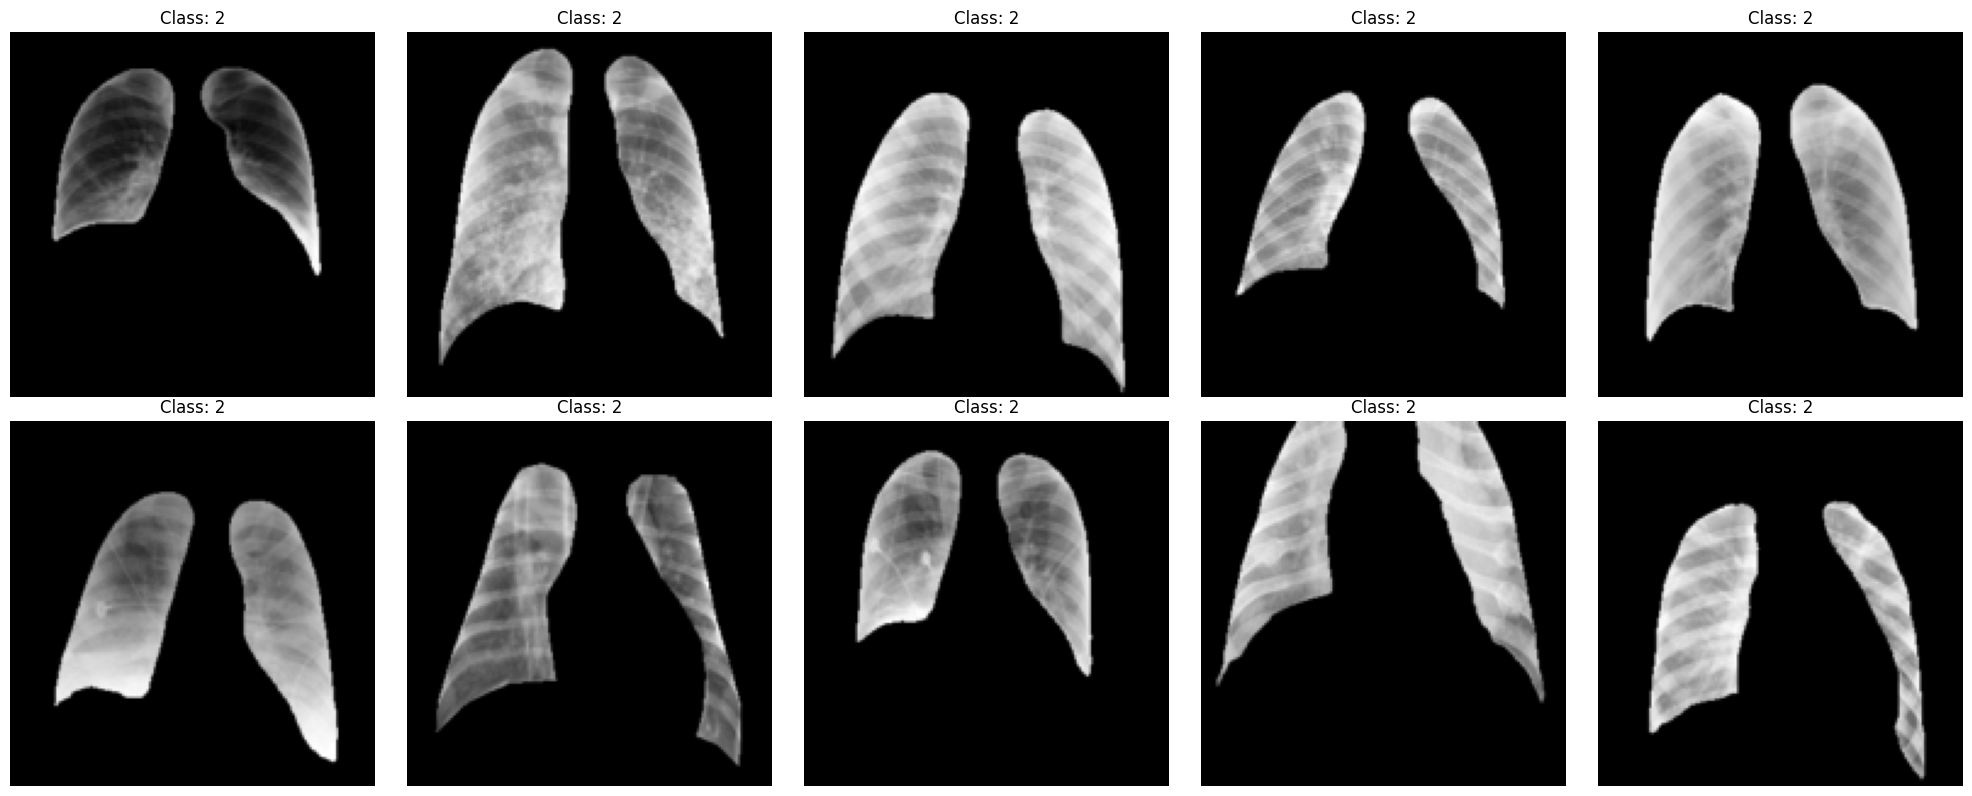

In [ ]:
# Отображаем 10 изображений класса "2"
fig, axs = plt.subplots(nrows=2, ncols=5, figsize=(20, 8))

for i, (image, label) in enumerate(class_2_dataset):
    if i >= 10:
        break

    row = i // 5
    col = i % 5

    ax = axs[row, col]
    ax.imshow(image.permute(1, 2, 0), cmap='gray')
    ax.set_title(f'Class: {label}')
    ax.axis('off')

plt.tight_layout()
plt.show()

Посмотрев на картинки, не видно чётко разницы между изображениями разных классов, но всё же отработаем и эту версию

### **Вспомогательные функции**

In [ ]:
def segmentation_train(model, optimizer, epoch, valid_loader):
    torch.save(model.state_dict(), '/content/drive/MyDrive/ModelsData/unet_model_w')
    torch.save(optimizer.state_dict(), '/content/drive/MyDrive/ModelsData/unet_optimizer')
    num_correct = 0
    num_pixel = 0
    dice_score = 0

    model.eval()
    with torch.no_grad():
        for x, y in valid_loader:
            x = x.to(device)
            y = y.to(device)

            preds = torch.sigmoid(model(x))
            preds = (preds > 0.5).float()

            num_correct += (preds == y).sum()
            num_pixel += torch.numel(preds)

            dice_score += (2 * (preds * y).sum()) / (
                (preds + y).sum() + 1e-8
            )

            torchvision.utils.save_image(preds, f"./test/pred/{epoch}.png")
            torchvision.utils.save_image(y, f"./test/true/{epoch}.png")

    print(
        f"Dice Score = {dice_score/len(val_dataset)}"
    )
    model.train()

In [ ]:
def segmentation_fit(model, train_loader, valid_loader, optimizer, loss_fn, num_epochs):
    step = 0
    for epoch in range(10):
        loop = tqdm(train_loader)
        for image, seg in loop:
            image = image.to(device)
            seg = seg.float().to(device)

            with torch.cuda.amp.autocast():
                pred = model(image)
                loss = loss_fn(pred, seg)

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            loop.set_postfix(loss=loss.item())
            step += 1
        segmentation_train(model, optimizer, epoch, valid_loader)

### **Трансформации**

In [ ]:
transforms_image = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0., 0., 0.), (1., 1., 1.))
])

transforms_mask = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize((0.,), (1.,))
])

### **Датасет для модели сегментации**

In [ ]:
class SegmentationDataset(Dataset):
    def __getitem__(self, index):
        image_name = self.images_paths[index]

        image = Image.open(os.path.join(self.image_dir, f"{image_name}")).convert("RGB")
        seg = Image.open(os.path.join(self.segmentation_dir, f"{image_name}")).convert("L")

        img = cv2.imread(os.path.join(self.image_dir, f"{image_name}"))
        image_bw = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        clahe = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8,8))
        final_img = clahe.apply(image_bw)
        final_img = cv2.cvtColor(final_img, cv2.COLOR_GRAY2RGB)

        image = self.transform_image(final_img)
        seg = self.transform_mask(seg)

        return image, seg

    def __init__(self):
        super(SegmentationDataset, self).__init__()
        self.image_dir = "./data/train_images"
        self.segmentation_dir = "./data/train_lung_masks"
        self.transform_image = transforms_image
        self.transform_mask = transforms_mask
        self.images_paths = [
            filename for filename in os.listdir(Path("data") / "train_images")
        ]

    def __len__(self):
        return len(self.images_paths)

### **Unet - моделька для сегментации**

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernal_size, strides, padding):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_segmentations=1, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.bottleneck = DoubleConv(
            in_channels=features[-1],
            out_channels=features[-1]*2,
            kernal_size=3,
            strides=1,
            padding=1
        )
        self.output = nn.Conv2d(
            in_channels=features[0],
            out_channels=num_segmentations,
            kernel_size=1
        )
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        in_channels_iter = in_channels
        for feature in features:
            self.downs.append(DoubleConv(
                    in_channels=in_channels_iter,
                    out_channels=feature,
                    kernal_size=3,
                    strides=1,
                    padding=1
                ))
            in_channels_iter = feature

        for feature in reversed(features):
            up = nn.Sequential(
                nn.ConvTranspose2d(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernel_size=2,
                    stride=2,
                    padding=0
                ),
                DoubleConv(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernal_size=3,
                    padding=1,
                    strides=1
                )
            )

            self.ups.append(up)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for i in range(len(self.ups)):
            x = self.ups[i][0](x)

            skip_connection = skip_connections[i]

            if x.shape != skip_connection.shape:
                x = TF.resize(x, size=skip_connection.shape[2:])

            concat_x = torch.cat((skip_connection, x), dim=1)

            x = self.ups[i][1](concat_x)

        return self.output(x)

### **Обучим модель для построения масок**

In [ ]:
if not os.path.exists('/content/test'):
    os.mkdir('/content/test')
if not os.path.exists('/content/test/true'):
    os.mkdir('/content/test/true')
if not os.path.exists('/content/test/pred'):
    os.mkdir('/content/test/pred')

In [ ]:
dataset = SegmentationDataset()

In [ ]:
train_dataset, val_dataset = random_split(dataset, [25000, 2000])
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
valid_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)

In [ ]:
unet_model = UNet(3).to(device)
optimizer = torch.optim.Adam(params=unet_model.parameters(), lr=1e-3)

In [ ]:
loss_fn = torch.nn.BCEWithLogitsLoss()
scaler = torch.cuda.amp.GradScaler()

In [ ]:
segmentation_fit(unet_model, train_loader, valid_loader, optimizer, loss_fn, 6)

### **Построим маски**

In [ ]:
unet_model = UNet(3).to(device)
unet_model.load_state_dict(torch.load('/content/drive/MyDrive/ModelsData/unet_model_w', map_location=torch.device('cpu')))

<All keys matched successfully>

In [ ]:
dataset_path = Path("./data/")
in_test_path = dataset_path /  "test_images"
out_path = dataset_path / "preprocessed_data"
out_test_masks_path = out_path / "test_images_masks"
if not os.path.exists(out_path):
    os.mkdir(out_path)
if not os.path.exists(out_test_masks_path):
    os.mkdir(out_test_masks_path)

transform_to_img = torchvision.transforms.ToPILImage()
transform_to_tensor = torchvision.transforms.ToTensor()
unet_model.eval()
with torch.no_grad():
  for filename in tqdm(os.listdir(in_test_path)):
        img = cv2.imread(str(in_test_path / filename))
        image_bw = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        clahe = cv2.createCLAHE(clipLimit=4.0, tileGridSize=(8,8))
        final_img = clahe.apply(image_bw)
        final_img = cv2.cvtColor(final_img, cv2.COLOR_GRAY2RGB)

        tensor = transform_to_tensor(final_img).to(device)
        preds = torch.sigmoid(unet_model(tensor.unsqueeze(0))).squeeze(0)
        preds = (preds > 0.5).float()
        mask = transform_to_img(preds)
        mask.save(out_test_masks_path / filename)


100%|██████████| 6920/6920 [03:01<00:00, 38.18it/s]


### **Теперь возьмем архитектуру самой удачной модели и обучим её уже на масках**

In [ ]:
model_6 = Model6().to(device)

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_6.parameters(), lr=1e-3)

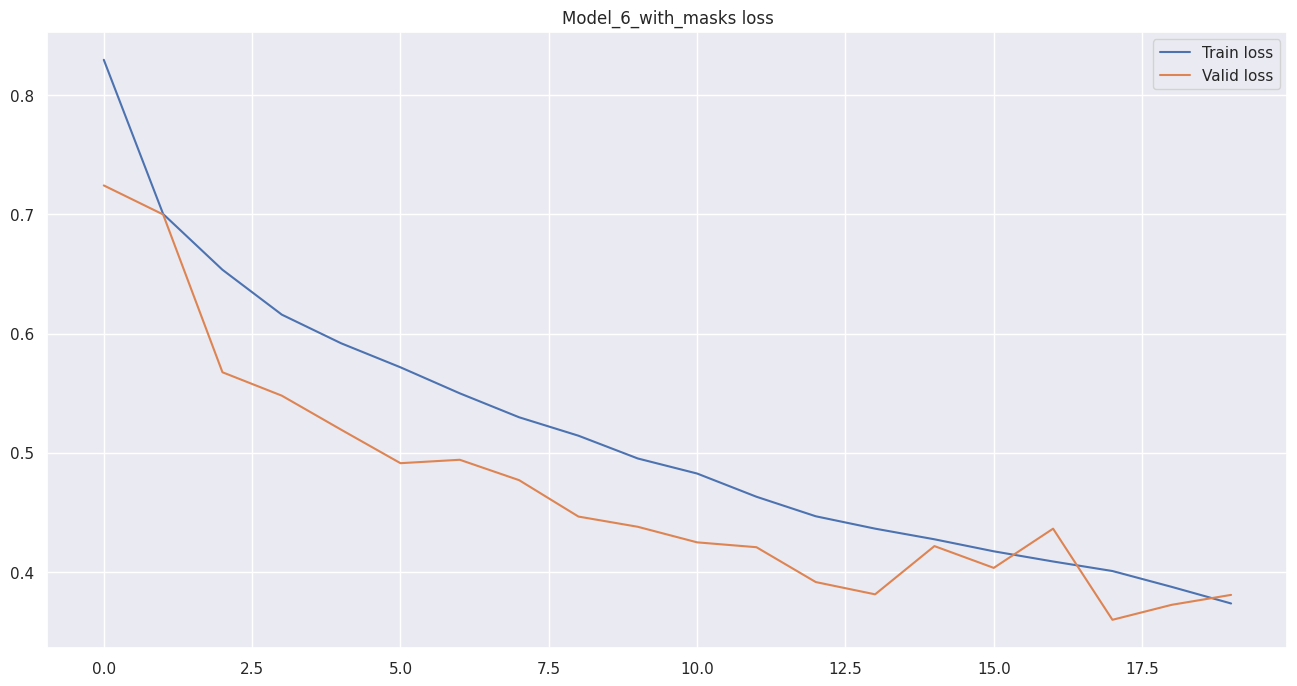

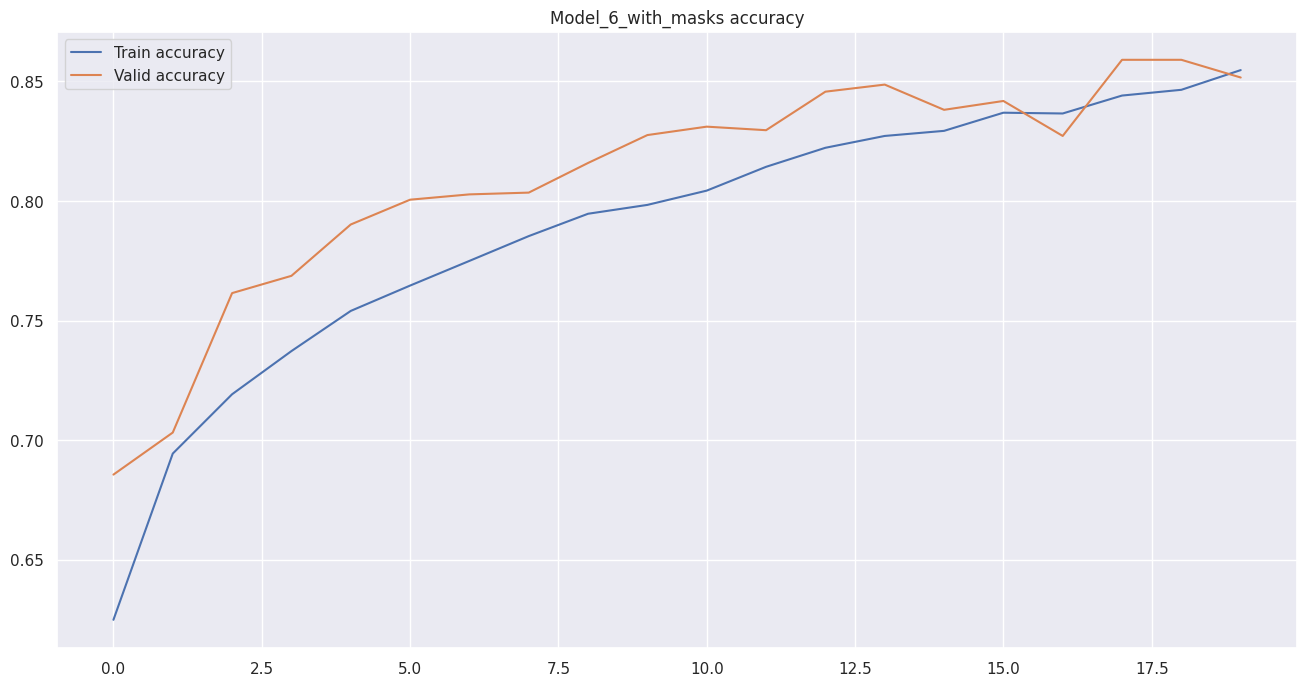

In [ ]:
fit(model_6, train_loader, valid_loader, optimizer, loss_fn, 20, 'Model_6_with_masks')

Все же маски не дали улучшения в показаниях :( Чтоб корректно определить класс надо видеть не только легкие (да и на треиновых масках есть прям сильно покоцанные легкие), но и еще знать что творится вокруг легких. Плюс тут еще играет роль не только точность модели для классификации, но и для сегментации (легкие могут криво вырезаться) -> шанс что где-то конечная модель накосячит больше. И в принципе осмотрев картинки видно, что даже треиновые маски не совсем корректные - на некоторых легкие прям ну сильно обрезаны, это связано с качеством снимков, на некоторых из них прям сильный завсет и легкие плохо видно (и это никак с болезнью не связано, т.е. на здоровых снимках тоже попадаются чисто белые). Но все же идея выглядела очень интересно и отработать её надо было обязательно

## **Выполняем предсказание на тестовом сете и скидываем все в csv файлик**

In [ ]:
load_model(model_7, '/content/drive/MyDrive/ModelsData/Model_7_w', map_location=torch.device('cpu'))

In [ ]:
def predict_classes():
    model_7.eval()
    res = []
    test_path = Path("./data/test_images")
    for i in tqdm(range(6920)):
        image_path = str(test_path / f"img_{i}.png")
        img = Image.open(image_path)

        # Закоменченные строки для масок

        # # Преобразование изображения в массив numpy
        # image_np = np.array(img)

        # mask_path = f'preprocessed_data/test_images_masks/img_{i}.png'

        # mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        # masked_image = cv2.bitwise_and(image_np, image_np, mask=mask)

        # # Преобразование обратно в изображение Pillow
        # img = Image.fromarray(masked_image)

        tensor = test_transform(img).unsqueeze(0).to(device)
        ans = torch.argmax(model_7(tensor))
        res.append([i, int(ans)])
    return res


res = predict_classes()

with open("/content/drive/MyDrive/Predictions/predictions.csv", "w") as f:
    writer = csv.writer(f, lineterminator="\n")
    writer.writerow(["id", "target_feature"])
    writer.writerows(res)

100%|██████████| 6920/6920 [1:02:22<00:00,  1.85it/s]


## **Сводная табличка :)**

<table>
  <tr>
    <th>Модель</th>
    <th>Loss</th>
    <th>Accuracy</th>
    <th>F1 Score</th>
  </tr>
  <tr>
    <td>Модель 1 (Простая линейная) + Аугментации №1</td>
    <td>0.852</td>
    <td>0.6925</td>
    <td>0.58750</td>
  </tr>
  <tr>
    <td>Модель 2 (ResNet34) + Аугментации №1</td>
    <td>0.6</td>
    <td>0.86</td>
    <td>0.70756</td>
  </tr>
  <tr>
    <td>Модель 3 (ResNet18) + Аугментации №1</td>
    <td>0.65</td>
    <td>0.83</td>
    <td>0.69001</td>
  </tr>
  <tr>
    <td>Модель 4 (Сверточная v1.0) + Аугментации №1</td>
    <td>0.35</td>
    <td>0.87</td>
    <td>0.45514</td>
  </tr>
  <tr>
    <td>Модель 5 (Сверточная v2.0) + Аугментации №1</td>
    <td>0.3</td>
    <td>0.88</td>
    <td>0.87766</td>
  </tr>
  <tr>
    <td>Модель 6 (Сверточная v3.0)) + Аугментации №1 -> ЛУЧШАЯ МОДЕЛЬ 🎉</td>
    <td>0.28</td>
    <td>0.88</td>
    <td>0.88721</td>
  </tr>
  <tr>
    <td>Модель 6 + маски + Аугментации №1</td>
    <td>0.38</td>
    <td>0.85</td>
    <td>0.41952</td>
  </tr>
  <tr>
    <td>Модель 7 (Сверточная v4.0)) + Аугментации №2</td>
    <td>0.33</td>
    <td>0.87</td>
    <td>0.79756</td>
  </tr>
</table>